In [10]:
import os
import random
import warnings
import datetime

import numpy as np
import pandas as pd
import geopandas as gpd
import xarray as xr
import rasterio
from rasterio.transform import xy

from scipy import interpolate
from scipy.signal import correlate

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.neighbors import KDTree, kneighbors_graph
from sklearn.manifold import TSNE, MDS

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Rectangle
import cartopy.crs as ccrs
import cartopy.feature as cfeature

import torch
import torch.nn.functional as F
from torch_geometric.nn import GATConv
from torch_geometric.data import Data

import umap

from libpysal.weights import W, WSP
from spopt.region import Skater, RegionKMeansHeuristic

from tslearn.metrics import cdist_dtw
from fastdtw import fastdtw
from dtaidistance import dtw

from dask import delayed, compute
from dask.diagnostics import ProgressBar

from tqdm import tqdm
from joblib import Parallel, delayed

warnings.filterwarnings('ignore')


def get_lat_lons(fname):
    """
    Extract latitude and longitude grids from a raster file.

    Parameters:
        fname (str): Path to the raster file.

    Returns:
        np.ndarray: A 3D numpy array with shape (2, height, width),
                    where the first layer contains latitudes and the second layer contains longitudes.
    """
    with rasterio.open(fname) as src:
        width = src.width
        height = src.height
        print('src width', width)
        print('src height', height)

        transform = src.transform

        rows, cols = np.meshgrid(np.arange(height), np.arange(width), indexing="ij")
        xs, ys = rasterio.transform.xy(transform, rows, cols, offset='center')

        lons = np.array(xs).reshape(height, width)
        lats = np.array(ys).reshape(height, width)

        latlon_grid = np.stack([lats, lons], axis=0)

        return latlon_grid


maize | Estonia | cpc-tmax.nc
       Value  Count
0 -26.490763     50
1 -26.456730    100
2 -26.362080    100
3 -26.319201     50
4 -26.186359    100
-26.490763
35.13619
src width 129
src height 44
Country Estonia, Start Date 1, End Date 242


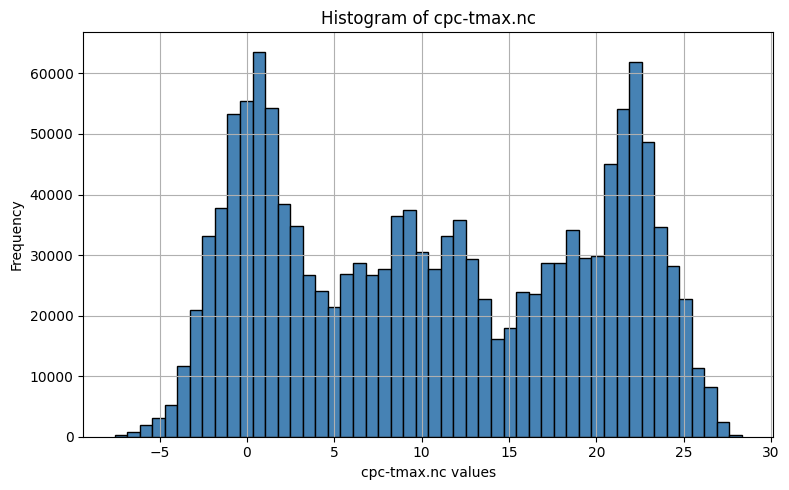

maize | Estonia | cpc-tmin.nc
       Value  Count
0 -34.867680    100
1 -34.377380     50
2 -34.360973    100
3 -34.170948     50
4 -34.160412    100
-34.86768
23.434467
src width 129
src height 44
Country Estonia, Start Date 1, End Date 242


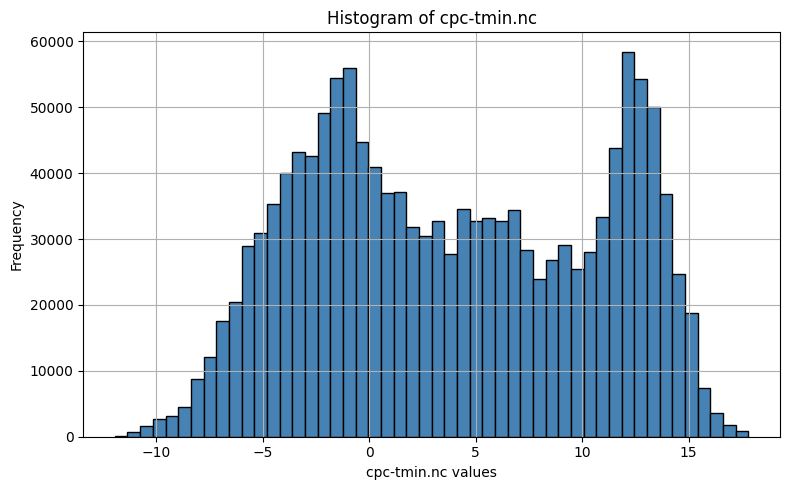

No extreme value found
maize | Estonia | esi-4wk.nc
        Value  Count
0 -143.771225      1
1  -18.668194      1
2   -8.012613      1
3   -7.900041      1
4   -4.089647      1
-143.77122
557.6955
src width 129
src height 44
Country Estonia, Start Date 1, End Date 242


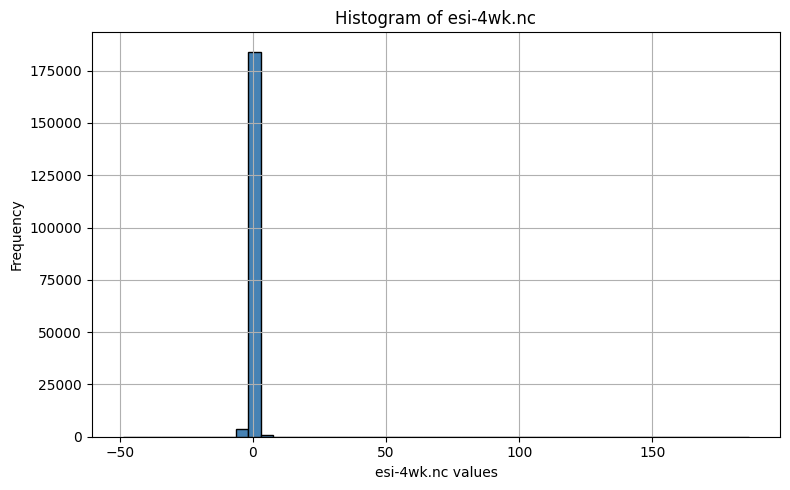

maize | Portugal | cpc-tmax.nc
       Value  Count
0 -16.653379    100
1  -7.691649    100
2  -5.313490     40
3  -4.753180     40
4  -4.053927     40
-16.65338
45.34586
src width 67
src height 104
Country Portugal, Start Date 1, End Date 242


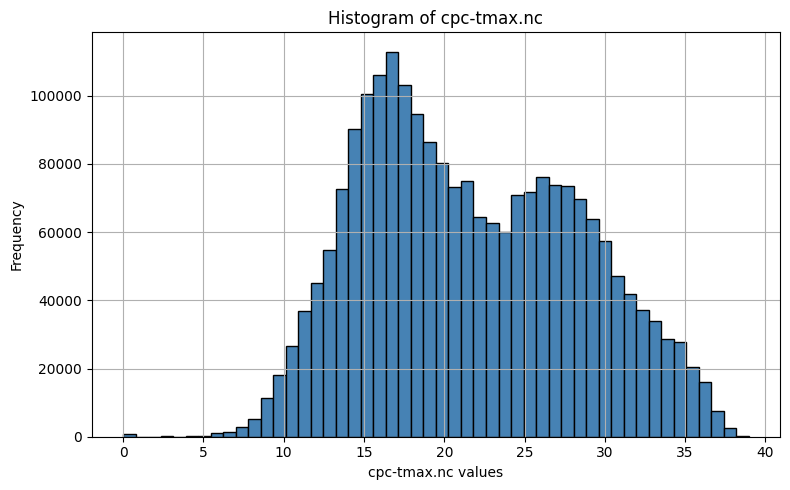

maize | Portugal | cpc-tmin.nc
       Value  Count
0 -16.653379    100
1 -11.665818     40
2 -11.166894     28
3 -10.554252     28
4 -10.490114     40
-16.65338
33.73929
src width 67
src height 104
Country Portugal, Start Date 1, End Date 242


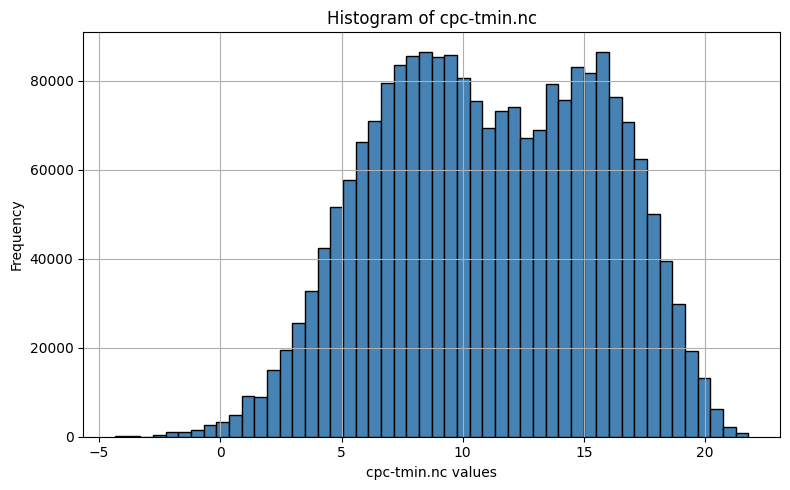

No extreme value found
maize | Portugal | esi-4wk.nc
      Value  Count
0 -4.666274      1
1 -4.504598      1
2 -4.442246      1
3 -4.070686      1
4 -4.058869      1
-4.6662736
3.5581412
src width 67
src height 104
Country Portugal, Start Date 1, End Date 242


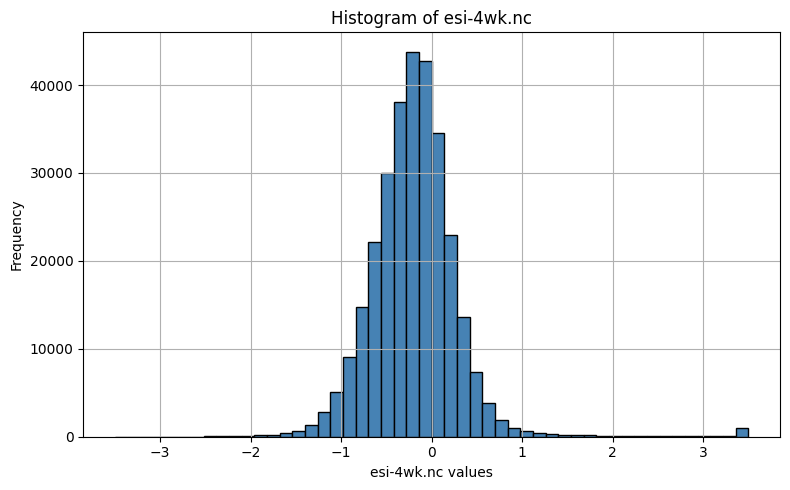

maize | Latvia | cpc-tmax.nc
       Value  Count
0 -26.858986    100
1 -26.648464    100
2 -26.611019    100
3 -26.551624     50
4 -26.490763     10
-26.858986
35.997787
src width 146
src height 50
Country Latvia, Start Date 1, End Date 242


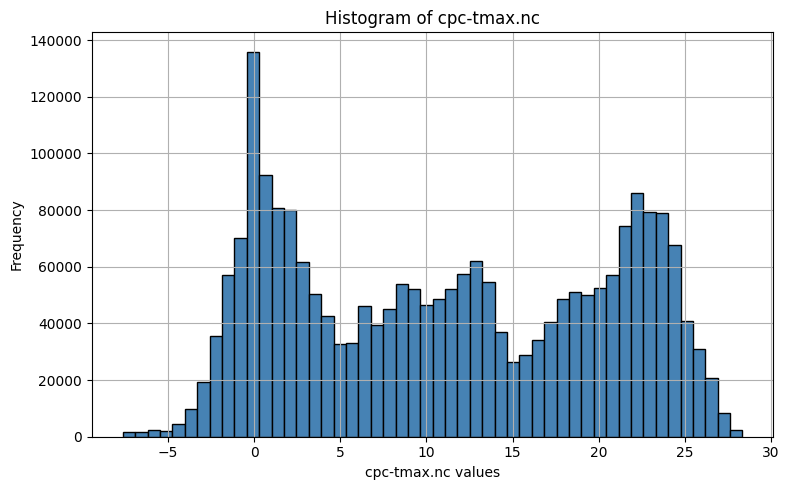

maize | Latvia | cpc-tmin.nc
       Value  Count
0 -34.867680    100
1 -34.377380     50
2 -34.360973    100
3 -34.170948     10
4 -34.160412    100
-34.86768
25.248957
src width 146
src height 50
Country Latvia, Start Date 1, End Date 242


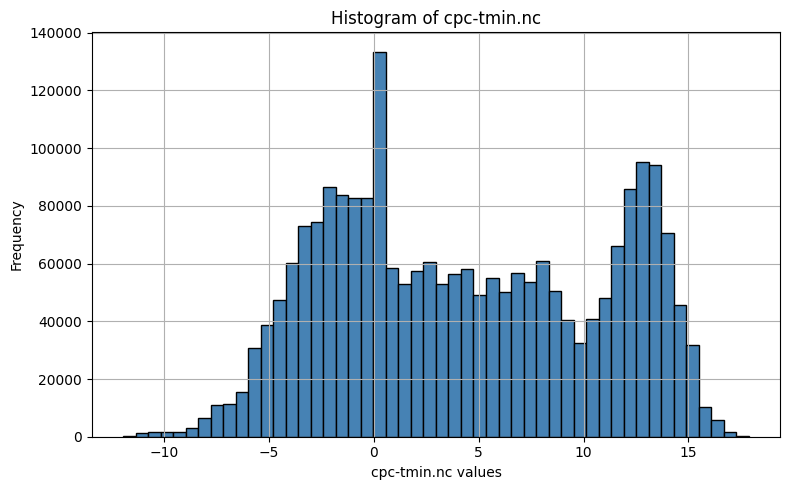

No extreme value found
maize | Latvia | esi-4wk.nc
        Value  Count
0 -143.771225      1
1   -8.012613      1
2   -7.900041      1
3   -3.696877      1
4   -3.500000   9489
-143.77122
13.972741
src width 146
src height 50
Country Latvia, Start Date 1, End Date 242


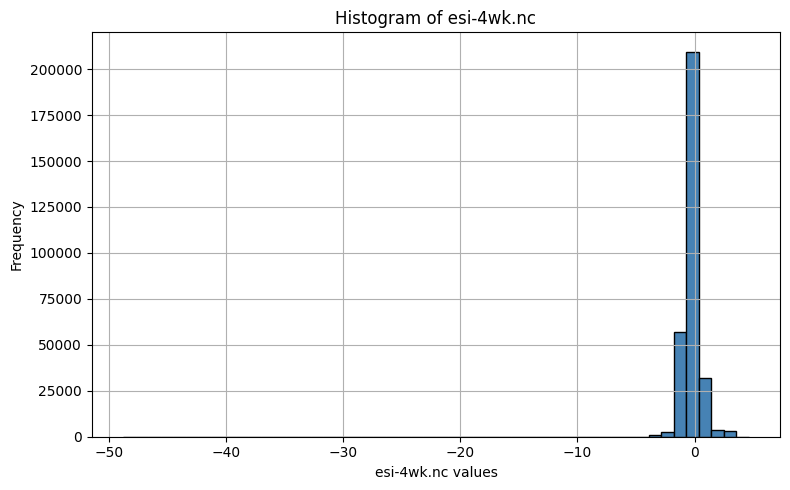

cereals | Estonia | cpc-tmax.nc
       Value  Count
0 -26.490763     50
1 -26.456730    100
2 -26.362080    100
3 -26.319201     50
4 -26.186359    100
-26.490763
35.13619
src width 129
src height 44
Country Estonia, Start Date 1, End Date 242


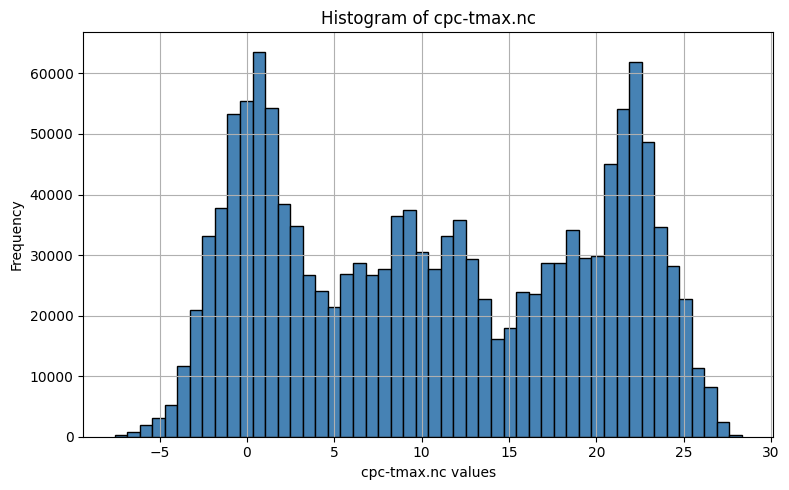

cereals | Estonia | cpc-tmin.nc
       Value  Count
0 -34.867680    100
1 -34.377380     50
2 -34.360973    100
3 -34.170948     50
4 -34.160412    100
-34.86768
23.434467
src width 129
src height 44
Country Estonia, Start Date 1, End Date 242


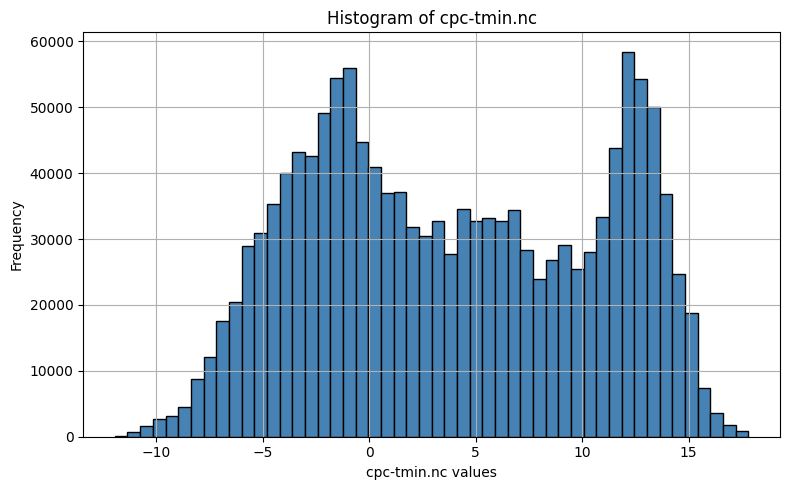

No extreme value found
cereals | Estonia | esi-4wk.nc
        Value  Count
0 -143.771225      1
1  -18.668194      1
2   -8.012613      1
3   -7.900041      1
4   -4.089647      1
-143.77122
557.6955
src width 129
src height 44
Country Estonia, Start Date 1, End Date 242


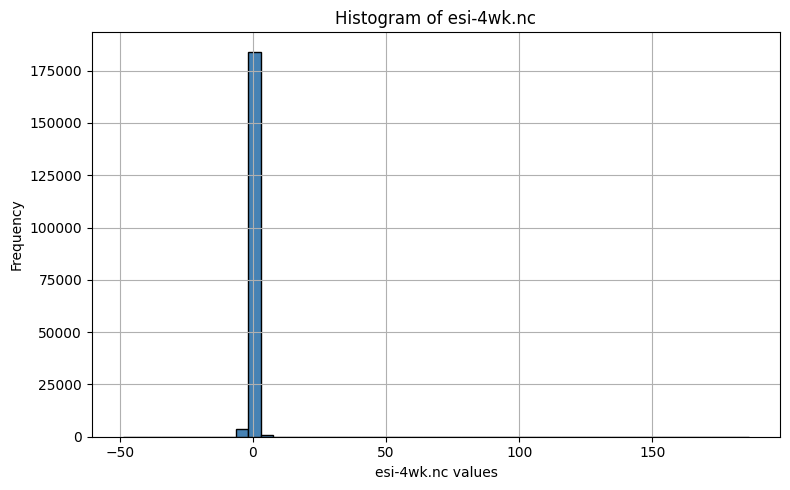

cereals | Portugal | cpc-tmax.nc
       Value  Count
0 -16.653379    100
1  -7.691649    100
2  -5.313490     40
3  -4.753180     40
4  -4.053927     40
-16.65338
45.34586
src width 67
src height 104
Country Portugal, Start Date 1, End Date 242


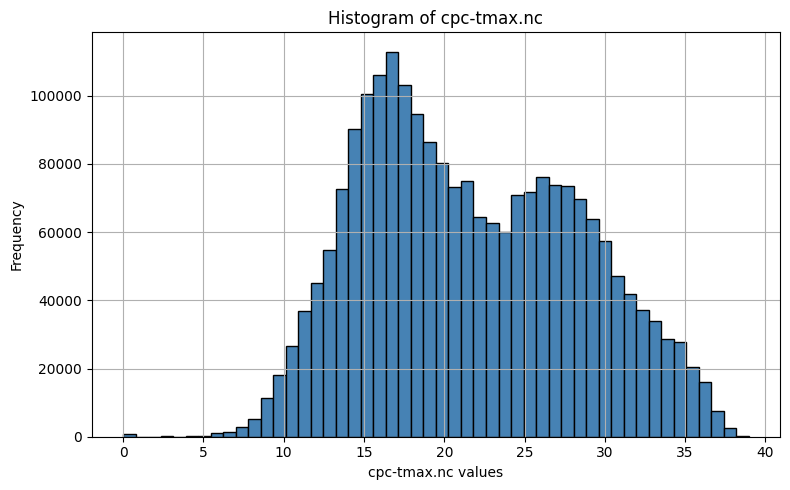

cereals | Portugal | cpc-tmin.nc
       Value  Count
0 -16.653379    100
1 -11.665818     40
2 -11.166894     28
3 -10.554252     28
4 -10.490114     40
-16.65338
33.73929
src width 67
src height 104
Country Portugal, Start Date 1, End Date 242


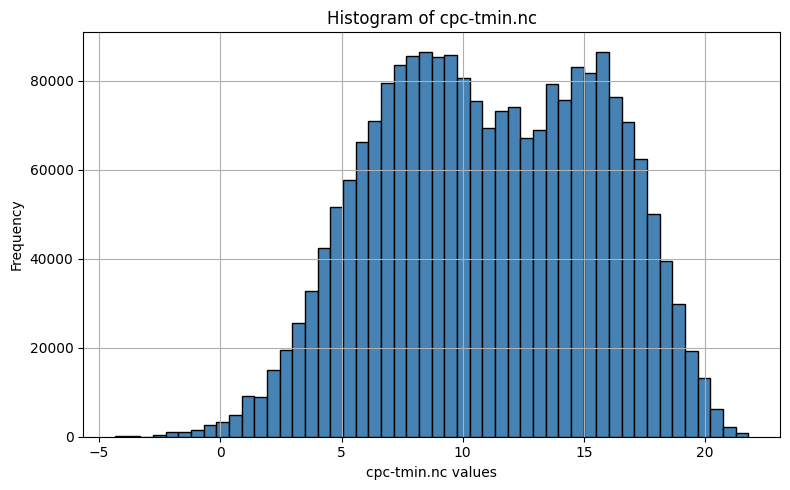

No extreme value found
cereals | Portugal | esi-4wk.nc
      Value  Count
0 -4.666274      1
1 -4.504598      1
2 -4.442246      1
3 -4.070686      1
4 -4.058869      1
-4.6662736
3.5581412
src width 67
src height 104
Country Portugal, Start Date 1, End Date 242


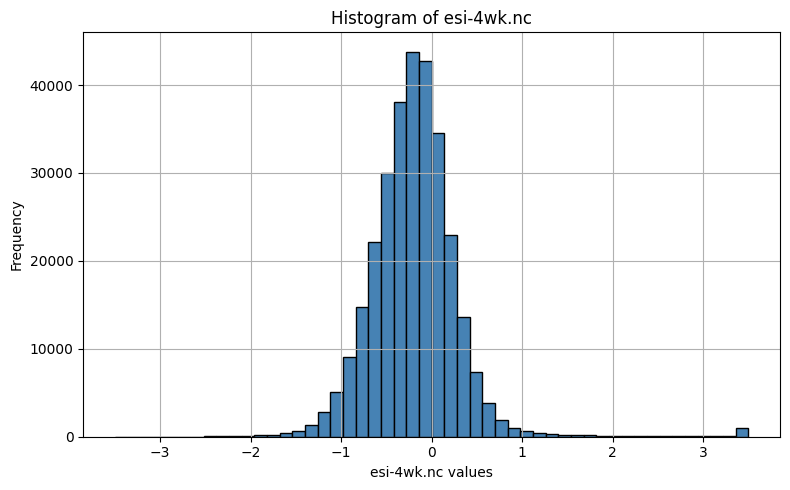

cereals | Latvia | cpc-tmax.nc
       Value  Count
0 -26.858986    100
1 -26.648464    100
2 -26.611019    100
3 -26.551624     50
4 -26.490763     10
-26.858986
35.997787
src width 146
src height 50
Country Latvia, Start Date 1, End Date 242


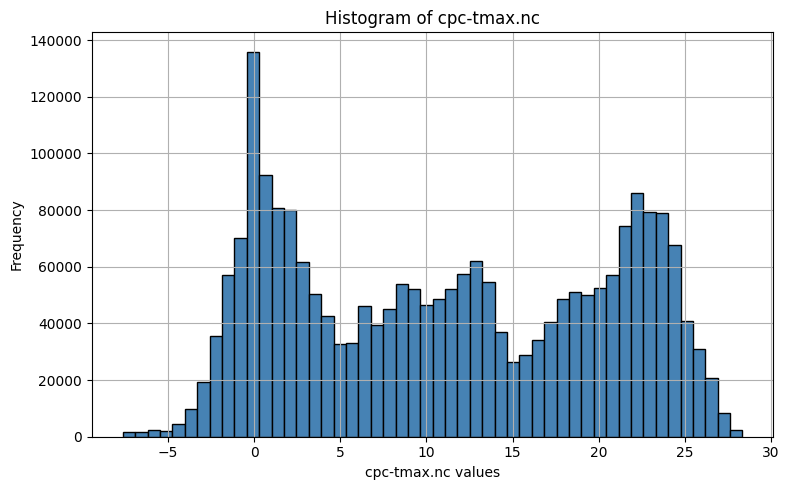

cereals | Latvia | cpc-tmin.nc
       Value  Count
0 -34.867680    100
1 -34.377380     50
2 -34.360973    100
3 -34.170948     10
4 -34.160412    100
-34.86768
25.248957
src width 146
src height 50
Country Latvia, Start Date 1, End Date 242


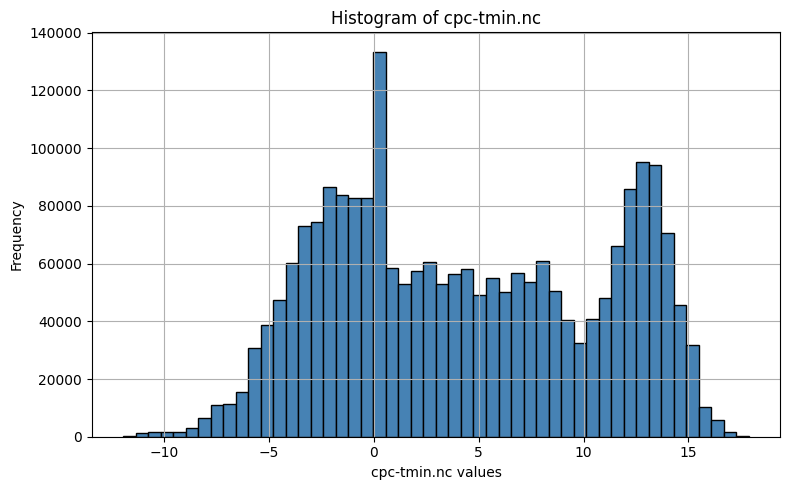

No extreme value found
cereals | Latvia | esi-4wk.nc
        Value  Count
0 -143.771225      1
1   -8.012613      1
2   -7.900041      1
3   -3.696877      1
4   -3.500000   9489
-143.77122
13.972741
src width 146
src height 50
Country Latvia, Start Date 1, End Date 242


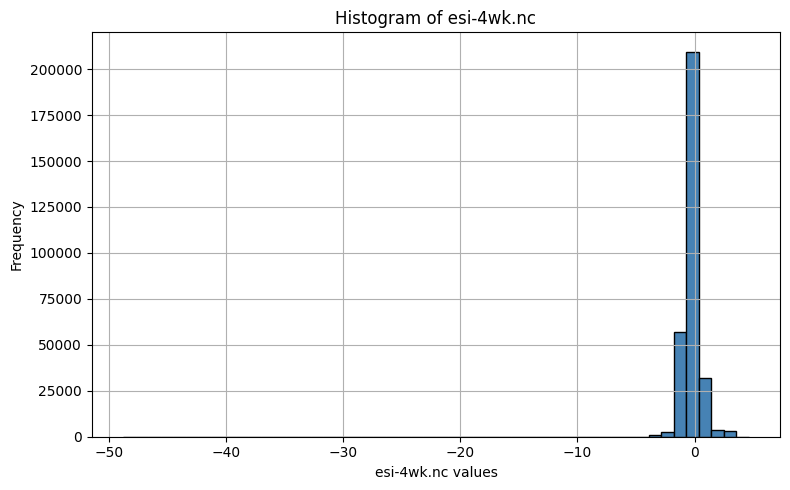

In [6]:
directory = r'C:\Users\shaba\Desktop\1.1 Crop ID - Domain Adaptation\decifr-ag\data\knowledge\zones\input'
out_directory = r'C:\Users\shaba\Desktop\1.1 Crop ID - Domain Adaptation\decifr-ag\data\knowledge\zones\output\shps\europe-cropindependent'
in_shp_directory = r'C:\Users\shaba\Desktop\1.1 Crop ID - Domain Adaptation\decifr-ag\data\knowledge\zones\shps'
out_shp_directory = r'C:\Users\shaba\Desktop\1.1 Crop ID - Domain Adaptation\decifr-ag\data\knowledge\zones\output\shps\europe-cropindependent'
paper_directory = r'C:\Users\shaba\Desktop\1.1 Crop ID - Domain Adaptation\decifr-ag\papers\zones_europe-cropindependent'

os.makedirs(directory, exist_ok=True)
os.makedirs(out_directory, exist_ok=True)
os.makedirs(in_shp_directory, exist_ok=True)
os.makedirs(out_shp_directory, exist_ok=True)
os.makedirs(paper_directory, exist_ok=True)

variables_init = [
    'fpar.nc',
    'ndvi.nc',
    'gcvi.nc',
    'cpc-tmax.nc',
    'cpc-tmin.nc',
    'esi-4wk.nc'
]

variables = {
    'fpar.nc':[255],
    'ndvi.nc':[0,255],
    'gcvi.nc':[-3000],
    'cpc-tmax.nc':[np.nan],
    'cpc-tmin.nc':[np.nan],
    'esi-4wk.nc':[-9999],
}

variables_init = [
    'cpc-tmax.nc',
    'cpc-tmin.nc',
    'esi-4wk.nc'
]

variables = {
    'cpc-tmax.nc':[np.nan],
    'cpc-tmin.nc':[np.nan],
    'esi-4wk.nc':[-9999],
}

countries = [
    'Estonia', 
    'Portugal', 
    'Latvia'
]

# countries = [
#     'Morocco'
# ]

use_crop_mask = False
crops = [
    'maize',
    'cereals'
]


datasets_all = {}
crop_mask_intensity = 5
slice_start_year = 2019
slice_end_year = 2023

# Crop Calendars
crop_cal = {
'maize': {
    'democratic_republic_of_the_congo': {'s1_startDate': '1/2', 's1_endDate': '30/9'},
    'uganda': {'s1_startDate': '15/3', 's1_endDate': '15/11'},
    'kenya': {'s1_startDate': '1/2', 's1_endDate': '30/9'},
    'zambia': {'s1_startDate': '1/2', 's1_endDate': '30/9'},
    'central_african_republic': {'s1_startDate': '1/3', 's1_endDate': '30/9'},
    'south_sudan': {'s1_startDate': '1/3', 's1_endDate': '30/10'},
    'ethiopia': {'s1_startDate': '15/4', 's1_endDate': '30/12'},
    'somalia': {'s1_startDate': '1/4', 's1_endDate': '30/8'},
    'mozambique': {'s1_startDate': '1/10', 's1_endDate': '30/5'},
    'united_republic_of_tanzania': {'s1_startDate': '1/9', 's1_endDate': '30/6'},
    'malawi': {'s1_startDate': '15/9', 's1_endDate': '15/6'},
    'burundi': {'s1_startDate': '1/2', 's1_endDate': '30/7'},
    'rwanda': {'s1_startDate': '1/2', 's1_endDate': '30/7'},
    'Estonia': {'s1_startDate': '1/3', 's1_endDate': '30/12'},
    'Portugal': {'s1_startDate': '1/3', 's1_endDate': '30/12'},
    'Latvia': {'s1_startDate': '1/3', 's1_endDate': '30/12'},
    'Morocco': {'s1_startDate': '1/1', 's1_endDate': '1/6'},
    },
'cereals': {
    'Estonia': {'s1_startDate': '1/1', 's1_endDate': '30/8'},
    'Portugal': {'s1_startDate': '1/1', 's1_endDate': '30/8'},
    'Latvia': {'s1_startDate': '1/1', 's1_endDate': '30/8'},
    'Morocco': {'s1_startDate': '1/1', 's1_endDate': '1/6'},
    },

}

data_freq = {}
data_freq_i = {}
shapes = {}

for crop in crops:
    for country in countries:
        for var_idx, var in enumerate(variables.keys()):
            ds_path = os.path.join(directory, country, var)
            dataset = xr.open_dataset(ds_path)
            var_name = list(dataset.data_vars)[0]
            data_var = dataset[var_name]

            valid_mask = xr.full_like(data_var, True, dtype=bool)
            for bad_val in variables[var]:
                if np.isnan(bad_val):
                    valid_mask &= ~np.isnan(data_var)
                else:
                    valid_mask &= (data_var != bad_val)

            data_var = data_var.where(valid_mask)
            dataset[var_name] = data_var
            flat = data_var.values.flatten()
            flat = flat[~np.isnan(flat)]

            for bad_val in variables[var]:
                if np.isnan(bad_val):
                    if np.isnan(flat).any():
                        raise ValueError(f"NaNs still present in {var} for {country}, {crop}")
                else:
                    if (flat == bad_val).any():
                        raise ValueError(f"Bad value {bad_val} still present in {var} for {country}, {crop}")
                    else:
                        print('No extreme value found')

            values, counts = np.unique(flat, return_counts=True)
            df_counts = pd.DataFrame({'Value': values, 'Count': counts})
            print(f"{crop} | {country} | {var}")
            print(df_counts.head())
            print(np.min(flat))
            print(np.max(flat))

            # Assign Height and Width as coordinates
            height_vals = dataset["height"].values
            width_vals = dataset["width"].values
            dataset = dataset.assign_coords(height=("height", height_vals), width=("width", width_vals))
            dataset = dataset.rename({"__xarray_dataarray_variable__": var})
            
            # Load Crop Mask
            if use_crop_mask:
                crop_mask = os.path.join(directory, country, "resampled_worldcereal", f"{crop}.tif")
                with rasterio.open(crop_mask, 'r') as cm:
                    arr = cm.read()[0, :, :]
            
            # Get Lat Lons and assign it to xarr
            region_mask = os.path.join(directory, country, "region_mask.tif")
            lat_lons= get_lat_lons(region_mask)
            dataset = dataset.assign_coords(lat=("lat", lat_lons[0, :, 0]), lon=("lon", lat_lons[1, 0, :]))
 
            def convert_to_day_of_year(date_str, year=2022):
                date_obj = datetime.datetime.strptime(f"{date_str}/{year}", "%d/%m/%Y")
                return date_obj.timetuple().tm_yday

            # Add day of year variable
            for _, regions in crop_cal.items():
                for region, calendar in regions.items():
                    if region == country: 
                        start_day_of_year = convert_to_day_of_year(calendar['s1_startDate'])
                        end_day_of_year = convert_to_day_of_year(calendar['s1_endDate'])

            print(f"Country {country}, Start Date {start_day_of_year}, End Date {end_day_of_year}")
            
            # Add growing season as a variable
            dataset["timestamps"] = pd.to_datetime(dataset["timestamps"].values)
            years = set([str(t).split('-')[0] for t in dataset["timestamps"].values])
            season_labels = np.full(dataset.dims["timestamps"], 0, dtype=object)

            for year in years:
                start_year = int(year)
                end_year = start_year if start_day_of_year < end_day_of_year else start_year + 1
                start_date = pd.to_datetime(f"{start_year}-01-01") + pd.to_timedelta(start_day_of_year - 1, unit='D')
                end_date = pd.to_datetime(f"{end_year}-01-01") + pd.to_timedelta(end_day_of_year - 1, unit='D')
                mask = (dataset["timestamps"].values >= start_date) & (dataset["timestamps"].values <= end_date)
                season_labels[mask] = int(start_year)

            # Assign season and dayofyear as coordinates
            dataset = dataset.assign_coords(
                season=("season", season_labels),
                dayofyear=("timestamps", dataset['timestamps'].dt.dayofyear.data)
            )

            # Slice by season and timestamps
            dataset_sliced = dataset.sel(
                season=slice(slice_start_year, slice_end_year),
                timestamps=slice(f'{slice_start_year}-01-01', f'{slice_end_year + 1}-12-31')
            )

            # Collapse timestamps by averaging over them, keeping dayofyear
            dataset_mean = dataset_sliced.groupby("dayofyear").mean(dim=["season", "timestamps"])
            dataset_mean = dataset_mean.drop_vars("timestamps", errors="ignore")

            # Mask out low intensity crop pixels
            if use_crop_mask:
                mask = arr > crop_mask_intensity
                mask_broadcasted = np.broadcast_to(mask, dataset_mean[var].shape)
                dataset_mean[var] = dataset_mean[var].where(mask_broadcasted)

            # append dataset
            datasets_all[(crop, country, var)] = dataset_mean[var].values
            sample_indices = random.sample(range(len(dataset_mean[var].values)), min(10, len(dataset_mean[var].values)))
            
            flattened_data = dataset_mean[var].values.ravel()
            flattened_data = flattened_data[~np.isnan(flattened_data)]
            plt.figure(figsize=(8, 5))
            plt.hist(flattened_data, bins=50, color='steelblue', edgecolor='black')
            plt.title(f'Histogram of {var}')
            plt.xlabel(f'{var} values')
            plt.ylabel('Frequency')
            plt.grid(True)
            plt.tight_layout()
            plt.show()
            
            plt.figure(figsize=(10, 6))
            for i in sample_indices:
                plt.plot(dataset_mean[var].values[:,40,5], alpha=0.7)
            plt.title(f'Normalized TS Samples - Variable {var}')
            plt.xlabel('Time Index')
            plt.ylabel('Normalized Value')
            plt.grid(True)
            plt.tight_layout()
            plt.savefig(rf'{paper_directory}\1_variable_{var}.png')
            plt.close()
            day_of_year = dataset_mean['dayofyear'].values
            day_diffs = np.diff(np.sort(day_of_year))
            median_frequency = np.median(day_diffs)
            data_freq[var] = median_frequency
            data_freq_i[var_idx] = median_frequency
        
        # Add lat lons and country shape
        datasets_all[(crop, country, 'lat')] = dataset_mean['lat'].values
        datasets_all[(crop, country, 'lon')] = dataset_mean['lon'].values
        shapes[country] = dataset_mean[var].shape



Temporal and Spatial Interpolation

In [7]:
import numpy as np
from scipy import interpolate

def temporal_interpolation(data):
    """
    Perform linear temporal interpolation on a 3D numpy array along the time axis.

    Parameters:
        data (np.ndarray): 3D array with shape (time_steps, width, height),
                           where some values may be NaN.

    Returns:
        np.ndarray: Interpolated data array of the same shape as input,
                    with NaNs replaced by linearly interpolated values over time.
    """
    time_steps, w, h = data.shape
    interpolated_data = np.copy(data)

    for w_idx in range(w):
        for h_idx in range(h):
            pixel_data = data[:, w_idx, h_idx]
            nan_indices = np.isnan(pixel_data)

            if np.all(nan_indices):
                continue

            interp_func = interpolate.interp1d(
                np.arange(time_steps)[~nan_indices],
                pixel_data[~nan_indices],
                kind='linear',
                fill_value="extrapolate"
            )
            interpolated_data[:, w_idx, h_idx] = interp_func(np.arange(time_steps))

    return interpolated_data


def spatial_interpolation(data):
    """
    Perform linear spatial interpolation on a 3D numpy array for each time step.

    Parameters:
        data (np.ndarray): 3D array with shape (time_steps, width, height),
                           where some spatial values at each time step may be NaN.

    Returns:
        np.ndarray: Interpolated data array of the same shape as input,
                    with NaNs replaced by spatially interpolated values within each time step.
    """
    time_steps = data.shape[0]
    width = data.shape[1]
    height = data.shape[2]

    x = np.arange(width)
    y = np.arange(height)
    xx, yy = np.meshgrid(x, y)

    interpolated_data = np.copy(data)

    for t in range(time_steps):
        spatial_data = data[t, :, :].flatten()
        nan_indices = np.isnan(spatial_data)

        if np.any(nan_indices):
            interpolator = interpolate.griddata(
                (xx.flatten()[~nan_indices], yy.flatten()[~nan_indices]),
                spatial_data[~nan_indices],
                (xx.flatten(), yy.flatten()),
                method='linear',
                fill_value=np.nan
            )
            interpolated_data[t, :, :] = interpolator.reshape(width, height)

    return interpolated_data


def interpolate_data(data):
    """
    Perform temporal interpolation on the input data.
    (Optional: perform spatial interpolation as well, currently commented out.)

    Parameters:
        data (np.ndarray): 3D array with shape (time_steps, width, height),
                           potentially containing NaNs.

    Returns:
        np.ndarray: Interpolated data after temporal (and optionally spatial) interpolation.
    """
    print(f'Temporal Interpolation {data.shape}')
    data = temporal_interpolation(data)

    # Uncomment below to perform spatial interpolation as well
    # data = spatial_interpolation(data)

    return data


Processing functions

In [8]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler, StandardScaler
import numpy as np

def reshape_data(data):
    """
    Reshape a 3D array by swapping axes and flattening the first two dimensions.

    Parameters:
        data (np.ndarray): Input array of shape (dim0, dim1, dim2).

    Returns:
        np.ndarray: Reshaped array of shape (dim0 * dim1, dim2).
    """
    swapped_data = np.swapaxes(data, 0, 1)
    swapped_data = np.swapaxes(swapped_data, 1, 2)
    reshaped_data = np.reshape(swapped_data, (swapped_data.shape[0] * swapped_data.shape[1], swapped_data.shape[2]))
    print(f"Reshaped data shape after two swaps and reshaping: {reshaped_data.shape}")
    return reshaped_data


def apply_pca(data, n_components=10):
    """
    Apply PCA with MinMax scaling to reduce data to a fixed number of components.

    Parameters:
        data (np.ndarray): Input data array.
        n_components (int): Number of PCA components to keep.

    Returns:
        np.ndarray: PCA-transformed data.
    """
    print(f"Data shape before PCA: {data.shape}")
    if data.shape[0] < n_components:
        print("Warning: Number of samples is less than n_components. Reducing n_components.")
        n_components = data.shape[0]

    data_reshaped = data.reshape(data.shape[0], -1)

    q01 = np.percentile(data_reshaped, 5, axis=0)
    q99 = np.percentile(data_reshaped, 95, axis=0)
    data_clipped = np.clip(data_reshaped, q01, q99)

    scaler = MinMaxScaler()
    data_scaled = scaler.fit_transform(data_clipped)

    pca = PCA(n_components=n_components)
    pca_values = pca.fit_transform(data_scaled)

    print('pc', pca_values.shape)
    return pca_values


def apply_pca(data, explained_variance_threshold=0.90):
    """
    Apply PCA with Standard scaling, selecting components based on explained variance threshold.

    Parameters:
        data (np.ndarray): Input data array.
        explained_variance_threshold (float): Threshold of cumulative variance to retain.

    Returns:
        np.ndarray: PCA-transformed data.
    """
    print(f"Data shape before preprocessing: {data.shape}")
    data = data.reshape(data.shape[0], -1)

    q01 = np.percentile(data, 5, axis=0)
    q99 = np.percentile(data, 95, axis=0)
    data_clipped = np.clip(data, q01, q99)

    scaler = StandardScaler()
    data_scaled = scaler.fit_transform(data_clipped)

    pca_full = PCA()
    pca_full.fit(data_scaled)

    cum_var = np.cumsum(pca_full.explained_variance_ratio_)
    print("Cumulative variance:", cum_var)

    n_components = np.searchsorted(cum_var, explained_variance_threshold) + 1
    print(f"Selected {n_components} components to capture {explained_variance_threshold * 100}% variance.")

    pca = PCA(n_components=n_components)
    pca_values = pca.fit_transform(data_scaled)

    print('PCA output shape:', pca_values.shape)
    return pca_values


def handle_nans(data):
    """
    Identify rows with any NaNs and return original data and a mask for rows with NaNs.

    Parameters:
        data (np.ndarray): Input data array.

    Returns:
        tuple: (original data, boolean mask of rows containing NaNs).
    """
    nan_rows = np.any(np.isnan(data), axis=1)
    print('nans', np.sum(nan_rows))
    return data, nan_rows


def perform_kmeans(data, kmeans, n_clusters=5):
    """
    Predict cluster labels for data using a fitted KMeans model.

    Parameters:
        data (np.ndarray): Data to cluster.
        kmeans (sklearn.cluster.KMeans): Pre-trained KMeans model.
        n_clusters (int): Number of clusters (not used inside function but kept for interface consistency).

    Returns:
        np.ndarray: Cluster labels.
    """
    return kmeans.predict(data)


def reshape_clustering_map(clusters, shape=(44, 129)):
    """
    Reshape a flat cluster label array to a 2D cluster map.

    Parameters:
        clusters (np.ndarray): Cluster labels in 1D.
        shape (tuple): Desired output shape.

    Returns:
        np.ndarray: 2D cluster map.
    """
    return clusters.reshape(shape)


Prep for clustering

In [9]:
def prep_for_clustering(data_list, var_list, country, shapes, mode, model):
    """
    Prepare and clean data for clustering by interpolating, reshaping, 
    handling NaNs, and extracting valid lat/lon coordinates.

    Parameters:
        data_list (list of np.ndarray): List of data arrays corresponding to variables.
        var_list (list of str): List of variable names corresponding to data_list.
        country (str): Country key to extract shape info.
        shapes (dict): Dictionary mapping country to shape info (rows, cols, time_steps).
        mode (str): Mode of operation (not used in this function but passed).
        model (any): Model parameter (not used in this function but passed).

    Returns:
        tuple:
            filtered_data_list (list of np.ndarray): List of cleaned and filtered data arrays without NaN rows.
            lat_lon (np.ndarray): 2D array of latitude and longitude for valid data points.
            mask (np.ndarray): Boolean mask array indicating valid data points (True) and NaNs (False).
    """
    cleaned_data_list = []
    nan_index_set = set()

    for idx, data_var in enumerate(data_list):
        var_name = var_list[idx]
        if var_name in variables_init and var_name not in ['lat', 'lon']:
            data_var = interpolate_data(data_var)
            reshaped_data = reshape_data(data_var)
            cleaned_data, nan_indices = handle_nans(reshaped_data)
            cleaned_data_list.append(cleaned_data)
            nan_index_set.update(np.where(nan_indices)[0])

    nan_index_list = sorted(nan_index_set)
    total_pixels = cleaned_data_list[0].shape[0]
    valid_indices = np.array([i for i in range(total_pixels) if i not in nan_index_list])

    filtered_data_list = [data[valid_indices, :] for data in cleaned_data_list]

    mask = np.ones(total_pixels, dtype=bool)
    mask[nan_index_list] = False

    lat_idx = [i for i, v in enumerate(var_list) if v == 'lat'][0]
    lon_idx = [i for i, v in enumerate(var_list) if v == 'lon'][0]

    lats = data_list[lat_idx]
    lons = data_list[lon_idx]

    n_rows = shapes[country][0]
    n_cols = shapes[country][1]

    lats_flat = np.repeat(lats[:, np.newaxis], shapes[country][2], axis=1).flatten()[valid_indices]
    lons_flat = np.repeat(lons[np.newaxis, :], shapes[country][1], axis=0).flatten()[valid_indices]

    lat_lon = np.column_stack((lats_flat, lons_flat))

    return filtered_data_list, lat_lon, mask


Load data, xarray operations and process over years

In [11]:
# directory = r'C:\Users\shaba\Desktop\1.1 Crop ID - Domain Adaptation\decifr-ag\data\knowledge\zones\input'
# out_directory = r'C:\Users\shaba\Desktop\1.1 Crop ID - Domain Adaptation\decifr-ag\data\knowledge\zones\output\shps\europe'
# in_shp_directory = r'C:\Users\shaba\Desktop\1.1 Crop ID - Domain Adaptation\decifr-ag\data\knowledge\zones\shps'
# out_shp_directory = r'C:\Users\shaba\Desktop\1.1 Crop ID - Domain Adaptation\decifr-ag\data\knowledge\zones\output\shps\europe'
# paper_directory = r'C:\Users\shaba\Desktop\1.1 Crop ID - Domain Adaptation\decifr-ag\papers\zones_europe'

# os.makedirs(directory, exist_ok=True)
# os.makedirs(out_directory, exist_ok=True)
# os.makedirs(in_shp_directory, exist_ok=True)
# os.makedirs(out_shp_directory, exist_ok=True)
# os.makedirs(paper_directory, exist_ok=True)

# variables_init = [
#     'fpar.nc',
#     'ndvi.nc',
#     'gcvi.nc',
#     'cpc-tmax.nc',
#     'cpc-tmin.nc',
#     'esi-4wk.nc'
# ]

# variables = {
#     'fpar.nc':[255],
#     'ndvi.nc':[0,255],
#     'gcvi.nc':[-3000],
#     'cpc-tmax.nc':[np.nan],
#     'cpc-tmin.nc':[np.nan],
#     'esi-4wk.nc':[-9999]
# }

# countries = [
#     'Estonia', 
#     'Portugal', 
#     'Latvia'
# ]

# # countries = [
# #     'Morocco'
# # ]

# use_crop_mask = True
# crops = [
#     'maize'
# ]


# datasets_all = {}
# crop_mask_intensity = 5
# slice_start_year = 2019
# slice_end_year = 2023

# # Crop Calendars
# crop_cal = {
# 'maize': {
#     'democratic_republic_of_the_congo': {'s1_startDate': '1/2', 's1_endDate': '30/9'},
#     'uganda': {'s1_startDate': '15/3', 's1_endDate': '15/11'},
#     'kenya': {'s1_startDate': '1/2', 's1_endDate': '30/9'},
#     'zambia': {'s1_startDate': '1/2', 's1_endDate': '30/9'},
#     'central_african_republic': {'s1_startDate': '1/3', 's1_endDate': '30/9'},
#     'south_sudan': {'s1_startDate': '1/3', 's1_endDate': '30/10'},
#     'ethiopia': {'s1_startDate': '15/4', 's1_endDate': '30/12'},
#     'somalia': {'s1_startDate': '1/4', 's1_endDate': '30/8'},
#     'mozambique': {'s1_startDate': '1/10', 's1_endDate': '30/5'},
#     'united_republic_of_tanzania': {'s1_startDate': '1/9', 's1_endDate': '30/6'},
#     'malawi': {'s1_startDate': '15/9', 's1_endDate': '15/6'},
#     'burundi': {'s1_startDate': '1/2', 's1_endDate': '30/7'},
#     'rwanda': {'s1_startDate': '1/2', 's1_endDate': '30/7'},
#     'Estonia': {'s1_startDate': '1/3', 's1_endDate': '30/12'},
#     'Portugal': {'s1_startDate': '1/3', 's1_endDate': '30/12'},
#     'Latvia': {'s1_startDate': '1/3', 's1_endDate': '30/12'},
#     'Morocco': {'s1_startDate': '1/1', 's1_endDate': '1/6'},
#     },
# 'cereals': {
#     'Estonia': {'s1_startDate': '1/1', 's1_endDate': '30/8'},
#     'Portugal': {'s1_startDate': '1/1', 's1_endDate': '30/8'},
#     'Latvia': {'s1_startDate': '1/1', 's1_endDate': '30/8'},
#     'Morocco': {'s1_startDate': '1/1', 's1_endDate': '1/6'},
#     },

# }

# data_freq = {}
# data_freq_i = {}
# shapes = {}

# for crop in crops:
#     for country in countries:
#         for var_idx, var in enumerate(variables.keys()):
#             ds_path = os.path.join(directory, country, var)
#             dataset = xr.open_dataset(ds_path)
#             var_name = list(dataset.data_vars)[0]
#             data_var = dataset[var_name]

#             valid_mask = xr.full_like(data_var, True, dtype=bool)
#             for bad_val in variables[var]:
#                 if np.isnan(bad_val):
#                     valid_mask &= ~np.isnan(data_var)
#                 else:
#                     valid_mask &= (data_var != bad_val)

#             data_var = data_var.where(valid_mask)
#             dataset[var_name] = data_var
#             flat = data_var.values.flatten()
#             flat = flat[~np.isnan(flat)]

#             for bad_val in variables[var]:
#                 if np.isnan(bad_val):
#                     if np.isnan(flat).any():
#                         raise ValueError(f"NaNs still present in {var} for {country}, {crop}")
#                 else:
#                     if (flat == bad_val).any():
#                         raise ValueError(f"Bad value {bad_val} still present in {var} for {country}, {crop}")
#                     else:
#                         print('No extreme value found')

#             values, counts = np.unique(flat, return_counts=True)
#             df_counts = pd.DataFrame({'Value': values, 'Count': counts})
#             print(f"{crop} | {country} | {var}")
#             print(df_counts.head())
#             print(np.min(flat))
#             print(np.max(flat))

#             # Assign Height and Width as coordinates
#             height_vals = dataset["height"].values
#             width_vals = dataset["width"].values
#             dataset = dataset.assign_coords(height=("height", height_vals), width=("width", width_vals))
#             dataset = dataset.rename({"__xarray_dataarray_variable__": var})
            
#             # Load Crop Mask
#             if use_crop_mask:
#                 crop_mask = os.path.join(directory, country, "resampled_worldcereal", f"{crop}.tif")
#                 with rasterio.open(crop_mask, 'r') as cm:
#                     arr = cm.read()[0, :, :]
            
#             # Get Lat Lons and assign it to xarr
#             region_mask = os.path.join(directory, country, "region_mask.tif")
#             lat_lons= get_lat_lons(region_mask)
#             dataset = dataset.assign_coords(lat=("lat", lat_lons[0, :, 0]), lon=("lon", lat_lons[1, 0, :]))
 
#             def convert_to_day_of_year(date_str, year=2022):
#                 date_obj = datetime.datetime.strptime(f"{date_str}/{year}", "%d/%m/%Y")
#                 return date_obj.timetuple().tm_yday

#             # Add day of year variable
#             for _, regions in crop_cal.items():
#                 for region, calendar in regions.items():
#                     if region == country: 
#                         start_day_of_year = convert_to_day_of_year(calendar['s1_startDate'])
#                         end_day_of_year = convert_to_day_of_year(calendar['s1_endDate'])

#             print(f"Country {country}, Start Date {start_day_of_year}, End Date {end_day_of_year}")
            
#             # Add growing season as a variable
#             dataset["timestamps"] = pd.to_datetime(dataset["timestamps"].values)
#             years = set([str(t).split('-')[0] for t in dataset["timestamps"].values])
#             season_labels = np.full(dataset.dims["timestamps"], 0, dtype=object)

#             for year in years:
#                 start_year = int(year)
#                 end_year = start_year if start_day_of_year < end_day_of_year else start_year + 1
#                 start_date = pd.to_datetime(f"{start_year}-01-01") + pd.to_timedelta(start_day_of_year - 1, unit='D')
#                 end_date = pd.to_datetime(f"{end_year}-01-01") + pd.to_timedelta(end_day_of_year - 1, unit='D')
#                 mask = (dataset["timestamps"].values >= start_date) & (dataset["timestamps"].values <= end_date)
#                 season_labels[mask] = int(start_year)

#             # Assign season and dayofyear as coordinates
#             dataset = dataset.assign_coords(
#                 season=("season", season_labels),
#                 dayofyear=("timestamps", dataset['timestamps'].dt.dayofyear.data)
#             )

#             # Slice by season and timestamps
#             dataset_sliced = dataset.sel(
#                 season=slice(slice_start_year, slice_end_year),
#                 timestamps=slice(f'{slice_start_year}-01-01', f'{slice_end_year + 1}-12-31')
#             )

#             # Collapse timestamps by averaging over them, keeping dayofyear
#             dataset_mean = dataset_sliced.groupby("dayofyear").mean(dim=["season", "timestamps"])
#             dataset_mean = dataset_mean.drop_vars("timestamps", errors="ignore")

#             # Mask out low intensity crop pixels
#             if use_crop_mask:
#                 mask = arr > crop_mask_intensity
#                 mask_broadcasted = np.broadcast_to(mask, dataset_mean[var].shape)
#                 dataset_mean[var] = dataset_mean[var].where(mask_broadcasted)

#             # append dataset
#             datasets_all[(crop, country, var)] = dataset_mean[var].values
#             sample_indices = random.sample(range(len(dataset_mean[var].values)), min(10, len(dataset_mean[var].values)))
            
#             flattened_data = dataset_mean[var].values.ravel()
#             flattened_data = flattened_data[~np.isnan(flattened_data)]
#             plt.figure(figsize=(8, 5))
#             plt.hist(flattened_data, bins=50, color='steelblue', edgecolor='black')
#             plt.title(f'Histogram of {var}')
#             plt.xlabel(f'{var} values')
#             plt.ylabel('Frequency')
#             plt.grid(True)
#             plt.tight_layout()
#             plt.show()
            
#             plt.figure(figsize=(10, 6))
#             for i in sample_indices:
#                 plt.plot(dataset_mean[var].values[:,40,5], alpha=0.7)
#             plt.title(f'Normalized TS Samples - Variable {var}')
#             plt.xlabel('Time Index')
#             plt.ylabel('Normalized Value')
#             plt.grid(True)
#             plt.tight_layout()
#             plt.savefig(rf'E:\CPUS\cpus\notebooks\normalized_ts_plots\1_variable_{var}.png')
#             plt.close()
#             day_of_year = dataset_mean['dayofyear'].values
#             day_diffs = np.diff(np.sort(day_of_year))
#             median_frequency = np.median(day_diffs)
#             data_freq[var] = median_frequency
#             data_freq_i[var_idx] = median_frequency
        
#         # Add lat lons and country shape
#         datasets_all[(crop, country, 'lat')] = dataset_mean['lat'].values
#         datasets_all[(crop, country, 'lon')] = dataset_mean['lon'].values
#         shapes[country] = dataset_mean[var].shape



In [12]:
import os
import logging
import random
import datetime
from typing import Dict, List, Tuple, Any

import numpy as np
import pandas as pd
import xarray as xr
import rasterio
import matplotlib.pyplot as plt


# ====================
# CONFIGURATION
# ====================
CONFIG = {
    "directories": {
        "input": r'C:\Users\shaba\Desktop\1.1 Crop ID - Domain Adaptation\decifr-ag\data\knowledge\zones\input',
        "output": r'C:\Users\shaba\Desktop\1.1 Crop ID - Domain Adaptation\decifr-ag\data\knowledge\zones\output\shps\europe',
        "input_shp": r'C:\Users\shaba\Desktop\1.1 Crop ID - Domain Adaptation\decifr-ag\data\knowledge\zones\input',
        "output_shp": r'C:\Users\shaba\Desktop\1.1 Crop ID - Domain Adaptation\decifr-ag\data\knowledge\zones\output\shps\europe',
        "papers": r'C:\Users\shaba\Desktop\1.1 Crop ID - Domain Adaptation\decifr-ag\papers\zones_europe',
        "plots": r'E:\CPUS\cpus\notebooks\normalized_ts_plots'
    },
    "variables": {
        'fpar.nc': [255],
        'ndvi.nc': [0, 255],
        'gcvi.nc': [-3000],
        'cpc-tmax.nc': [np.nan],
        'cpc-tmin.nc': [np.nan],
        'esi-4wk.nc': [-9999]
    },
    "countries": ['Estonia', 'Portugal', 'Latvia'],
    "use_crop_mask": True,
    "crops": ['maize'],
    "crop_mask_intensity": 5,
    "slice_year_start": 2019,
    "slice_year_end": 2023,
    "crop_calendar": {
        'maize': {
            'democratic_republic_of_the_congo': {'s1_startDate': '1/2', 's1_endDate': '30/9'},
            'uganda': {'s1_startDate': '15/3', 's1_endDate': '15/11'},
            'kenya': {'s1_startDate': '1/2', 's1_endDate': '30/9'},
            'zambia': {'s1_startDate': '1/2', 's1_endDate': '30/9'},
            'central_african_republic': {'s1_startDate': '1/3', 's1_endDate': '30/9'},
            'south_sudan': {'s1_startDate': '1/3', 's1_endDate': '30/10'},
            'ethiopia': {'s1_startDate': '15/4', 's1_endDate': '30/12'},
            'somalia': {'s1_startDate': '1/4', 's1_endDate': '30/8'},
            'mozambique': {'s1_startDate': '1/10', 's1_endDate': '30/5'},
            'united_republic_of_tanzania': {'s1_startDate': '1/9', 's1_endDate': '30/6'},
            'malawi': {'s1_startDate': '15/9', 's1_endDate': '15/6'},
            'burundi': {'s1_startDate': '1/2', 's1_endDate': '30/7'},
            'rwanda': {'s1_startDate': '1/2', 's1_endDate': '30/7'},
            'Estonia': {'s1_startDate': '1/3', 's1_endDate': '30/12'},
            'Portugal': {'s1_startDate': '1/3', 's1_endDate': '30/12'},
            'Latvia': {'s1_startDate': '1/3', 's1_endDate': '30/12'},
            'Morocco': {'s1_startDate': '1/1', 's1_endDate': '1/6'},
        },
        'cereals': {
            'Estonia': {'s1_startDate': '1/1', 's1_endDate': '30/8'},
            'Portugal': {'s1_startDate': '1/1', 's1_endDate': '30/8'},
            'Latvia': {'s1_startDate': '1/1', 's1_endDate': '30/8'},
            'Morocco': {'s1_startDate': '1/1', 's1_endDate': '1/6'},
        }
    }
}


# ====================
# SETUP LOGGING
# ====================
logging.basicConfig(
    level=logging.INFO,
    format='[%(asctime)s] %(levelname)s: %(message)s',
    handlers=[
        logging.StreamHandler()
    ]
)
logger = logging.getLogger(__name__)


# ====================
# UTILITIES
# ====================
def get_lat_lons(region_mask_path: str) -> np.ndarray:
    """
    Extract latitude and longitude grids from a raster region mask.
    
    Parameters:
    -----------
    region_mask_path : str
        Path to the region mask raster file.
    
    Returns:
    --------
    np.ndarray
        2D arrays of latitudes and longitudes
    """
    with rasterio.open(region_mask_path) as src:
        bounds = src.bounds
        width = src.width
        height = src.height
        
        lon = np.linspace(bounds.left, bounds.right, width)
        lat = np.linspace(bounds.top, bounds.bottom, height)
        lat_grid, lon_grid = np.meshgrid(lat, lon, indexing='ij')
        return np.array([lat_grid, lon_grid])


def convert_to_day_of_year(date_str: str, year: int = 2022) -> int:
    """
    Convert a date string (format 'd/m') to day of year integer.
    
    Parameters:
    -----------
    date_str : str
        Date string in format 'd/m' (e.g., '1/3').
    year : int
        Year to use for conversion (default 2022).
    
    Returns:
    --------
    int
        Day of year corresponding to the input date.
    """
    date_obj = datetime.datetime.strptime(f"{date_str}/{year}", "%d/%m/%Y")
    return date_obj.timetuple().tm_yday


# ====================
# CORE PROCESSING FUNCTIONS
# ====================
def load_and_clean_dataset(ds_path: str, bad_values: List[Any]) -> xr.Dataset:
    """
    Load an xarray Dataset and mask out bad values.
    
    Parameters:
    -----------
    ds_path : str
        Path to the NetCDF dataset.
    bad_values : list
        List of bad values to mask out (including np.nan).
    
    Returns:
    --------
    xr.Dataset
        Cleaned dataset with bad values masked out.
    """
    try:
        ds = xr.open_dataset(ds_path)
    except FileNotFoundError as e:
        logger.error(f"File not found: {ds_path}")
        raise e

    var_name = list(ds.data_vars)[0]
    data_var = ds[var_name]

    valid_mask = xr.full_like(data_var, True, dtype=bool)
    for bad_val in bad_values:
        if np.isnan(bad_val):
            valid_mask &= ~np.isnan(data_var)
        else:
            valid_mask &= (data_var != bad_val)

    cleaned_var = data_var.where(valid_mask)
    ds[var_name] = cleaned_var
    return ds


def assign_coords_and_mask(dataset: xr.Dataset, lat_lons: np.ndarray, use_crop_mask: bool,
                           crop_mask_path: str, crop_mask_intensity: int) -> Tuple[xr.Dataset, np.ndarray]:
    """
    Assign latitude and longitude coordinates to the dataset,
    and load crop mask array if requested.
    
    Parameters:
    -----------
    dataset : xr.Dataset
        Dataset to modify.
    lat_lons : np.ndarray
        Latitude and longitude arrays.
    use_crop_mask : bool
        Whether to load crop mask.
    crop_mask_path : str
        Path to crop mask raster.
    crop_mask_intensity : int
        Threshold intensity for masking crop pixels.
    
    Returns:
    --------
    tuple:
        - xr.Dataset with lat/lon coords assigned.
        - numpy.ndarray of crop mask array if used, else None.
    """
    dataset = dataset.assign_coords(
        lat=("lat", lat_lons[0, :, 0]),
        lon=("lon", lat_lons[1, 0, :])
    )

    crop_mask_arr = None
    if use_crop_mask:
        try:
            with rasterio.open(crop_mask_path) as cm:
                crop_mask_arr = cm.read(1)
        except FileNotFoundError:
            logger.warning(f"Crop mask file not found: {crop_mask_path}")
    return dataset, crop_mask_arr


def assign_season_and_dayofyear(dataset: xr.Dataset, crop_cal: Dict[str, Dict[str, Dict[str, str]]],
                                crop: str, country: str) -> xr.Dataset:
    """
    Assign 'season' and 'dayofyear' coordinates to dataset timestamps
    based on crop calendar for given crop and country.
    
    Parameters:
    -----------
    dataset : xr.Dataset
        Dataset with timestamps coordinate.
    crop_cal : dict
        Crop calendar dict with start/end dates.
    crop : str
        Crop name.
    country : str
        Country name.
    
    Returns:
    --------
    xr.Dataset
        Dataset with season and dayofyear coordinates added.
    """
    dataset["timestamps"] = pd.to_datetime(dataset["timestamps"].values)
    
    # Get crop calendar for the country
    try:
        calendar = crop_cal[crop][country.lower()]
    except KeyError:
        calendar = crop_cal[crop].get(country, None)
    if calendar is None:
        logger.warning(f"No crop calendar found for crop={crop}, country={country}. Season assignment skipped.")
        dataset = dataset.assign_coords(season=("timestamps", np.nan))
        dataset = dataset.assign_coords(dayofyear=("timestamps", dataset['timestamps'].dt.dayofyear.data))
        return dataset

    start_day_of_year = convert_to_day_of_year(calendar['s1_startDate'])
    end_day_of_year = convert_to_day_of_year(calendar['s1_endDate'])

    years = set(str(pd.Timestamp(t).year) for t in dataset["timestamps"].values)
    season_labels = np.full(dataset.dims["timestamps"], np.nan)

    for year_str in years:
        start_year = int(year_str)
        end_year = start_year if start_day_of_year < end_day_of_year else start_year + 1
        start_date = pd.to_datetime(f"{start_year}-01-01") + pd.to_timedelta(start_day_of_year - 1, unit='D')
        end_date = pd.to_datetime(f"{end_year}-01-01") + pd.to_timedelta(end_day_of_year - 1, unit='D')

        mask = (dataset["timestamps"].values >= start_date) & (dataset["timestamps"].values <= end_date)
        season_labels[mask] = start_year

    dataset = dataset.assign_coords(
        season=("timestamps", season_labels),
        dayofyear=("timestamps", dataset['timestamps'].dt.dayofyear.data)
    )
    logger.info(f"Assigned season for crop {crop}, country {country} from day {start_day_of_year} to {end_day_of_year}")
    return dataset


def slice_and_aggregate(dataset: xr.Dataset, slice_start_year: int, slice_end_year: int,
                        crop_mask_arr: np.ndarray, crop_mask_intensity: int, var: str,
                        use_crop_mask: bool) -> xr.Dataset:
    """
    Slice dataset by season and timestamps, then aggregate by dayofyear.
    
    Parameters:
    -----------
    dataset : xr.Dataset
        Dataset with season and timestamps.
    slice_start_year : int
        Start year for slicing.
    slice_end_year : int
        End year for slicing.
    crop_mask_arr : np.ndarray
        Crop mask array if used.
    crop_mask_intensity : int
        Threshold intensity for masking crop pixels.
    var : str
        Variable name in dataset.
    use_crop_mask : bool
        Whether to apply crop mask filtering.
    
    Returns:
    --------
    xr.Dataset
        Aggregated dataset grouped by dayofyear.
    """
    # Filter timestamps in range
    ds_filtered = dataset.sel(
        timestamps=slice(f"{slice_start_year}-01-01", f"{slice_end_year + 1}-12-31")
    )

    # Mask out timestamps outside season range
    ds_filtered = ds_filtered.where(
        (ds_filtered.season >= slice_start_year) & (ds_filtered.season <= slice_end_year)
    ).dropna(dim="timestamps", how="all")

    # Group by dayofyear and average over timestamps
    ds_mean = ds_filtered.groupby("dayofyear").mean(dim="timestamps")
    ds_mean = ds_mean.drop_vars("timestamps", errors="ignore")

    # Apply crop mask if enabled
    if use_crop_mask and crop_mask_arr is not None:
        mask = crop_mask_arr > crop_mask_intensity
        if var in ds_mean.data_vars:
            # Broadcast mask to variable's shape if needed
            var_shape = ds_mean[var].shape
            if mask.shape != var_shape[-2:]:
                logger.warning(f"Crop mask shape {mask.shape} doesn't match data var spatial shape {var_shape[-2:]}")
            mask_broadcasted = np.broadcast_to(mask, var_shape)
            ds_mean[var] = ds_mean[var].where(mask_broadcasted)
        else:
            logger.warning(f"Variable {var} not found in dataset when applying crop mask.")

    return ds_mean


def plot_histogram_and_timeseries(data: np.ndarray, var: str, output_dir: str) -> None:
    """
    Plot histogram and sample time series from data array.
    
    Parameters:
    -----------
    data : np.ndarray
        Data array to plot.
    var : str
        Variable name.
    output_dir : str
        Directory to save plots.
    """
    clean_data = data.ravel()
    clean_data = clean_data[~np.isnan(clean_data)]
    plt.figure(figsize=(8, 5))
    plt.hist(clean_data, bins=50, color='steelblue', edgecolor='black')
    plt.title(f'Histogram of {var}')
    plt.xlabel(f'{var} values')
    plt.ylabel('Frequency')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(10, 6))
    sample_indices = random.sample(range(len(data)), min(10, len(data)))
    for i in sample_indices:
        plt.plot(data[i, 40, 5], alpha=0.7)
    plt.title(f'Normalized TS Samples - Variable {var}')
    plt.xlabel('Time Index')
    plt.ylabel('Normalized Value')
    plt.grid(True)
    plt.tight_layout()
    plot_path = os.path.join(output_dir, f"1_variable_{var}.png")
    plt.savefig(plot_path)
    plt.close()
    logger.info(f"Saved time series plot for {var} at {plot_path}")


# ====================
# MAIN PROCESSING FUNCTION
# ====================
def main_process(config: Dict) -> None:
    """
    Main processing pipeline for loading datasets, cleaning,
    assigning seasons, slicing, aggregating, and plotting.
    
    Parameters:
    -----------
    config : dict
        Configuration dictionary.
    """
    # Create directories if they don't exist
    for key, dir_path in config["directories"].items():
        os.makedirs(dir_path, exist_ok=True)
        logger.info(f"Directory ready: {dir_path}")

    datasets_all = {}
    data_freq = {}
    data_freq_i = {}
    shapes = {}

    for crop in config["crops"]:
        for country in config["countries"]:
            logger.info(f"Processing crop: {crop}, country: {country}")

            for var_idx, var in enumerate(config["variables"].keys()):
                ds_path = os.path.join(config["directories"]["input"], country, var)
                
                # Load and clean dataset
                dataset = load_and_clean_dataset(ds_path, config["variables"][var])
                var_name = list(dataset.data_vars)[0]
                
                # Assign height and width coords explicitly
                height_vals = dataset["height"].values
                width_vals = dataset["width"].values
                dataset = dataset.assign_coords(height=("height", height_vals), width=("width", width_vals))
                dataset = dataset.rename({var_name: var})

                # Load crop mask if enabled
                crop_mask_arr = None
                if config["use_crop_mask"]:
                    crop_mask_path = os.path.join(config["directories"]["input"], country, "resampled_worldcereal", f"{crop}.tif")
                else:
                    crop_mask_path = None

                # Get lat/lon from region mask
                region_mask_path = os.path.join(config["directories"]["input"], country, "region_mask.tif")
                lat_lons = get_lat_lons(region_mask_path)

                # Assign lat/lon coords and load crop mask array if needed
                dataset, crop_mask_arr = assign_coords_and_mask(dataset, lat_lons, config["use_crop_mask"], crop_mask_path, config["crop_mask_intensity"])

                # Assign season and dayofyear coords based on crop calendar
                dataset = assign_season_and_dayofyear(dataset, config["crop_calendar"], crop, country)

                # Slice dataset by year and season, aggregate by dayofyear
                dataset_mean = slice_and_aggregate(
                    dataset, config["slice_year_start"], config["slice_year_end"],
                    crop_mask_arr, config["crop_mask_intensity"], var, config["use_crop_mask"]
                )

                # Store for later or saving
                key = (crop, country, var)
                datasets_all[key] = dataset_mean[var].values
                data_freq[key] = dataset_mean[var].shape[0]  # number of days in growing season
                data_freq_i[key] = dataset_mean[var].shape[0]
                shapes[key] = dataset_mean[var].shape

                # Optional plots
                # if var_idx == 0:
                plot_histogram_and_timeseries(datasets_all[key], var, config["directories"]["plots"])
    return datasets_all, data_freq_i, shapes
    logger.info("Processing completed.")


# # ====================
# # RUN SCRIPT
# # ====================
# # if __name__ == "__main__":
# try:
#     datasets_all, data_freq_i, shapes = main_process(CONFIG)
# except Exception as e:
#     logger.exception(f"Unexpected error during processing: {e}")


Clustering Algos

In [13]:
import numpy as np
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.neighbors import kneighbors_graph
from sklearn.neighbors import KDTree
import networkx as nx
import torch
import torch.nn.functional as F
from torch_geometric.nn import GATConv
from torch_geometric.data import Data
from libpysal.weights import W, WSP, weights
from spopt.region import RegionKMeansHeuristic
from spopt.region import Skater


def best_k_via_internal_metrics(data, clustering_func, spatial=None, base_params=None):
    """
    Determines the optimal number of clusters (k) using internal metrics: 
    Silhouette Score and Davies-Bouldin Index.

    Args:
        data (np.ndarray): Concatenated feature matrix of shape (n_samples, n_features).
        clustering_func (function): Clustering function to evaluate.
        spatial (np.ndarray, optional): Spatial coordinates (n_samples, 2).
        base_params (dict, optional): Base parameters passed to clustering_func.

    Returns:
        int: Estimated best number of clusters.
    """
    scores = []
    k_range = range(3, 20)
    for k in k_range:
        params = dict(base_params or {})
        params['n_clusters'] = k
        params['optimize'] = False
        try:
            labels = clustering_func(spatial, data, params)
            if isinstance(labels, tuple):
                labels = labels[0]
            sil = silhouette_score(np.concatenate([np.array(item) for item in data], axis=1), labels)
            dbi = davies_bouldin_score(np.concatenate([np.array(item) for item in data], axis=1), labels)
            scores.append((k, sil, dbi))
        except Exception:
            continue
    if not scores:
        return 5
    scores = np.array(scores)
    sil_rank = scores[:, 1].argsort()[::-1]
    dbi_rank = scores[:, 2].argsort()
    final_rank = sil_rank + dbi_rank
    best_k = scores[final_rank.argmin(), 0]
    return int(best_k)


def kmeans_clustering(spatial, data, params):
    """
    Perform standard KMeans clustering.

    Args:
        spatial (np.ndarray): Spatial coordinates (ignored here).
        data (list of arrays or np.ndarray): Feature data.
        params (dict): Parameters including 'n_clusters' and 'optimize'.

    Returns:
        np.ndarray: Cluster labels.
    """
    data = np.concatenate([np.array(item) for item in data], axis=1)
    if params.get('optimize', True):
        params['n_clusters'] = best_k_via_internal_metrics(data, kmeans_clustering, spatial, params)
    kmeans = KMeans(n_clusters=params['n_clusters'], random_state=42)
    return kmeans.fit_predict(data)

from pysal.lib import weights
def regional_kmeansheuristic(spatial, data, params):
    """
    Perform spatially constrained KMeans clustering using RegionKMeansHeuristic.

    Args:
        spatial (np.ndarray): Spatial coordinates (lat, lon).
        data (list of arrays or np.ndarray): Feature data.
        params (dict): Parameters including 'n_clusters', 'drop_islands', 'seed', 'optimize'.

    Returns:
        np.ndarray: Cluster labels.
    """
    data = np.concatenate([np.array(item) for item in data], axis=1)
    if params.get('optimize', True):
        params['n_clusters'] = best_k_via_internal_metrics(data, regional_kmeansheuristic, spatial, params)
    
    drop_islands = params.get('drop_islands', True)
    seed = params.get('seed', 0)
    
    gdf = gpd.GeoDataFrame(pd.DataFrame(data), geometry=gpd.points_from_xy(spatial[:, 1], spatial[:, 0]))
    gdf.crs = "EPSG:4326"
    
    coords = np.array(list(zip(gdf.geometry.x, gdf.geometry.y)))
    w = weights.DistanceBand(coords, threshold=40.0)
    
    model = RegionKMeansHeuristic(data=np.array(data), n_clusters=params['n_clusters'], w=w,
                                 drop_islands=drop_islands, seed=seed)
    model.solve()
    return model.labels_


def fast_skater(spatial, data, params):
    """
    Fast SKATER clustering algorithm using minimum spanning tree partitioning.

    Args:
        spatial (np.ndarray): Spatial coordinates.
        data (list of arrays or np.ndarray): Feature data.
        params (dict): Parameters including 'n_clusters', 'k_neighbors', 'optimize'.

    Returns:
        np.ndarray: Cluster labels.
    """
    data = np.column_stack(data)
    if params.get('optimize', True):
        params['n_clusters'] = best_k_via_internal_metrics(data, fast_skater, spatial, params)

    k_neighbors = min(params['k_neighbors'], len(spatial) - 1)
    connectivity = kneighbors_graph(spatial, k_neighbors, mode='connectivity', include_self=False)
    
    G = nx.Graph()
    rows, cols = connectivity.nonzero()
    for i, j in zip(rows, cols):
        if i < j:
            G.add_edge(i, j)
    
    mst = nx.minimum_spanning_tree(G)
    
    for u, v in mst.edges():
        mst[u][v]['var'] = np.var(np.vstack([data[u], data[v]]), axis=0).sum()
    
    for _ in range(params['n_clusters'] - 1):
        u, v, _ = max(mst.edges(data=True), key=lambda x: x[2]['var'])
        mst.remove_edge(u, v)
    
    components = list(nx.connected_components(mst))
    labels = np.empty(len(spatial), dtype=int)
    for i, comp in enumerate(components):
        for idx in comp:
            labels[idx] = i
    return labels


def skater_clustering(spatial, data, params):
    """
    Spatially constrained clustering using SKATER algorithm.

    Args:
        spatial (np.ndarray): Spatial coordinates (lat, lon).
        data (list of arrays or np.ndarray): Feature data.
        params (dict): Parameters including 'n_clusters', 'k_neighbors', 'optimize'.

    Returns:
        np.ndarray: Cluster labels.
    """
    data = np.concatenate([np.array(item) for item in data], axis=1)
    if params.get('optimize', True):
        params['n_clusters'] = best_k_via_internal_metrics(data, skater_clustering, spatial, params)
    
    k_neighbors = min(max(params['k_neighbors'], int(np.log2(len(spatial)))), len(spatial) - 2)
    tree = KDTree(spatial)
    neighbors = tree.query(spatial, k=k_neighbors + 1)[1][:, 1:]
    neighbors_dict = {i: list(neighbors[i]) for i in range(len(neighbors))}
    
    spatial_weights = W(neighbors_dict)
    spatial_weights = WSP(spatial_weights.sparse)
    
    df = pd.DataFrame(data)
    gdf = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(spatial[:, 1], spatial[:, 0]))
    gdf.crs = "EPSG:4326"
    
    skater_obj = Skater(gdf, w=spatial_weights, attrs_name=df.columns, n_clusters=params['n_clusters'])
    skater_obj.solve()
    return skater_obj.labels_


class GATEncoder(torch.nn.Module):
    """
    Graph Attention Network (GAT) encoder module for feature embedding.
    """
    def __init__(self, in_channels, hidden_channels, out_channels, heads=4, dropout=0.6):
        super(GATEncoder, self).__init__()
        self.conv1 = GATConv(in_channels, hidden_channels, heads=heads, dropout=dropout)
        self.conv2 = GATConv(hidden_channels * heads, out_channels, heads=1, dropout=dropout)

    def forward(self, data):
        x, edge_index = data.x, data.edge_index
        x = F.elu(self.conv1(x, edge_index))
        x = self.conv2(x, edge_index)
        return x


def prepare_graph_data(spatial, data):
    """
    Prepare graph data object for PyTorch Geometric from spatial and feature data.

    Args:
        spatial (np.ndarray): Spatial coordinates (n_samples, 2).
        data (list of arrays or np.ndarray): Feature data.

    Returns:
        torch_geometric.data.Data: Graph data with features and edges.
    """
    x = torch.tensor(np.concatenate([np.array(item) for item in data], axis=1), dtype=torch.float)
    num_nodes = x.shape[0]
    edge_index = [[i, j] for i in range(num_nodes) for j in range(num_nodes) if i != j]
    edge_index = torch.tensor(edge_index, dtype=torch.long).t().contiguous()
    return Data(x=x, edge_index=edge_index)


def target_distribution(q):
    """
    Calculate target distribution for clustering refinement.

    Args:
        q (torch.Tensor): Soft cluster assignments (n_samples x n_clusters).

    Returns:
        torch.Tensor: Target distribution.
    """
    p = q ** 2 / q.sum(0, keepdim=True)
    return p / p.sum(1, keepdim=True)


def kl_loss(q, p):
    """
    Compute KL divergence loss between distributions q and p.

    Args:
        q (torch.Tensor): Predicted distribution.
        p (torch.Tensor): Target distribution.

    Returns:
        torch.Tensor: KL divergence loss.
    """
    return torch.sum(p * torch.log((p + 1e-10) / (q + 1e-10)))


def GAT_DEC_clustering(spatial, data, params):
    """
    Graph Attention Network-based Deep Embedded Clustering (GAT-DEC).

    Args:
        spatial (np.ndarray): Spatial coordinates.
        data (list of arrays or np.ndarray): Feature data.
        params (dict): Parameters including 'n_clusters' and 'optimize'.

    Returns:
        tuple: Cluster assignments (np.ndarray), learned embeddings (np.ndarray).
    """
    if params.get('optimize', True):
        # Run best_k_via_internal_metrics with optimize=False to avoid recursion
        params['n_clusters'] = best_k_via_internal_metrics(data, GAT_DEC_clustering, spatial, dict(params, optimize=False))
    
    graph_data = prepare_graph_data(spatial, data)
    in_dim = graph_data.x.shape[1]
    embedding_dim = 16
    n_clusters = params.get('n_clusters', 3)

    encoder = GATEncoder(in_channels=in_dim, hidden_channels=16, out_channels=embedding_dim)
    model = encoder
    optimizer = torch.optim.Adam(model.parameters(), lr=0.005)
    cluster_centers = torch.randn(n_clusters, embedding_dim, requires_grad=True)

    for epoch in range(100):
        model.train()
        optimizer.zero_grad()
        z = model(graph_data)
        dist = torch.cdist(z, cluster_centers)
        q = torch.softmax(-dist, dim=1)
        p = target_distribution(q)
        loss = kl_loss(q, p)
        loss.backward()
        optimizer.step()

    model.eval()
    with torch.no_grad():
        z = model(graph_data)
        dist = torch.cdist(z, cluster_centers)
        q = torch.softmax(-dist, dim=1)
        cluster_assignments = torch.argmax(q, dim=1)

    return cluster_assignments.numpy(), z.detach().numpy()


Specify Regions and aggregation level

In [14]:
# LEVEL 1, 2, 3, CUSTOM, NATIVE
shapefile_prt_path = rf'C:\Users\shaba\Desktop\1.1 Crop ID - Domain Adaptation\decifr-ag\data\knowledge\zones\shps\Portugal\gadm41_PRT_2.shp'
shapefile_lva_path = rf'C:\Users\shaba\Desktop\1.1 Crop ID - Domain Adaptation\decifr-ag\data\knowledge\zones\shps\Latvia\gadm41_LVA_2.shp'
shapefile_est_path = rf'C:\Users\shaba\Desktop\1.1 Crop ID - Domain Adaptation\decifr-ag\data\knowledge\zones\shps\Estonia\gadm41_EST_2.shp'
level = 'GID_2'
gdf_prt = gpd.read_file(shapefile_prt_path)
gdf_lva = gpd.read_file(shapefile_lva_path)
gdf_est = gpd.read_file(shapefile_est_path)
shps = [gdf_prt, gdf_lva, gdf_est]
for i in range(len(shps)):
    shps[i] = shps[i].to_crs("EPSG:4326")
shps_combined = gpd.GeoDataFrame(pd.concat(shps, ignore_index=True), crs="EPSG:4326")

# shapefile_mar_path = rf'{in_shp_directory}\gadm41_MAR_shp\gadm41_MAR_4.shp'
# level = 'GID_4'
# gdf_mar = gpd.read_file(shapefile_mar_path)
# shps = [gdf_mar]

def aggregator(data, coords, shps, level):
    df = pd.DataFrame(coords, columns=['lat', 'lon'])
    df['geometry'] = df.apply(lambda r: Point(r['lon'], r['lat']), axis=1)
    gdf = gpd.GeoDataFrame(df, geometry='geometry', crs="EPSG:4326")
    
    for i in range(len(shps)):
        shps[i] = shps[i].to_crs("EPSG:4326")

    shps_combined = gpd.GeoDataFrame(pd.concat(shps, ignore_index=True), crs="EPSG:4326")
    joined = gpd.sjoin(left_df=gdf, right_df=shps_combined, how='left', predicate='within')
    right_geom = shps_combined.reset_index()[['index', 'geometry']].rename(columns={'geometry': 'geometry_shp'})
    joined = joined.merge(right_geom, left_on='index_right', right_on='index', how='left')

    labels = np.array(list(joined[level]))
    labels = labels.ravel().astype(str)
    X = data.astype(np.float64)
    valid_mask = (~np.isin(labels, ['nan', 'None'])) & (~np.isnan(X).all(axis=1))
    X_valid = X[valid_mask]
    labels_valid = labels[valid_mask]
    unique_labels, inverse_indices = np.unique(labels_valid, return_inverse=True)
    n_features = X.shape[1]
    n_groups = len(unique_labels)
    group_sums = np.zeros((n_groups, n_features))
    group_counts = np.zeros((n_groups, n_features))
    
    for i in range(n_features):
        x_col = X_valid[:, i]
        mask = ~np.isnan(x_col)
        group_sums[:, i] = np.bincount(inverse_indices[mask], weights=x_col[mask], minlength=n_groups)
        group_counts[:, i] = np.bincount(inverse_indices[mask], minlength=n_groups)
    group_means = group_sums / group_counts
    group_means[np.isnan(group_means)] = np.nan

    level_unique_geoms = joined[[level, 'geometry_shp']].dropna()
    unique_geoms = level_unique_geoms.drop_duplicates(subset=[level])
    label_to_geom = dict(zip(unique_geoms[level].astype(str), unique_geoms['geometry_shp']))
    ordered_geometries = [label_to_geom.get(label, None) for label in unique_labels]
    ordered_centroids = [
        label_to_geom[label].centroid if label in label_to_geom and label_to_geom[label] is not None else None
        for label in unique_labels
    ]

    return group_means, unique_labels, joined, ordered_centroids, ordered_geometries



[2025-05-26 22:19:17,532] ERROR: PROJ: proj_identify: C:\ProgramData\anaconda3\envs\decifr\Library\share\proj\proj.db lacks DATABASE.LAYOUT.VERSION.MAJOR / DATABASE.LAYOUT.VERSION.MINOR metadata. It comes from another PROJ installation.
[2025-05-26 22:19:17,558] ERROR: PROJ: proj_identify: C:\ProgramData\anaconda3\envs\decifr\Library\share\proj\proj.db lacks DATABASE.LAYOUT.VERSION.MAJOR / DATABASE.LAYOUT.VERSION.MINOR metadata. It comes from another PROJ installation.
[2025-05-26 22:19:19,507] ERROR: PROJ: proj_identify: C:\ProgramData\anaconda3\envs\decifr\Library\share\proj\proj.db lacks DATABASE.LAYOUT.VERSION.MAJOR / DATABASE.LAYOUT.VERSION.MINOR metadata. It comes from another PROJ installation.
[2025-05-26 22:19:19,524] ERROR: PROJ: proj_identify: C:\ProgramData\anaconda3\envs\decifr\Library\share\proj\proj.db lacks DATABASE.LAYOUT.VERSION.MAJOR / DATABASE.LAYOUT.VERSION.MINOR metadata. It comes from another PROJ installation.
[2025-05-26 22:19:19,571] ERROR: PROJ: proj_identify

Plot functions

In [15]:
import matplotlib.cm as cm 

def add_north_arrow(ax):
    ax.annotate('N', xy=(0.05, 0.95), xycoords='axes fraction', fontsize=14, color='black', fontweight='bold', ha='center')

def add_scale_bar(ax):
    ax.plot([0.05, 0.15], [0.05, 0.05], color="black", lw=3)
    ax.text(0.1, 0.03, "1000 km", transform=ax.transAxes, fontsize=12, color='black', va='center')

# Combine tab20, tab20b, and tab20c for more variety
tab20_colors = list(plt.cm.get_cmap('tab20').colors)
tab20b_colors = list(plt.cm.get_cmap('tab20b').colors)
tab20c_colors = list(plt.cm.get_cmap('tab20c').colors)

# Combine and truncate to 30 colors
fixed_colors = (tab20_colors + tab20b_colors + tab20c_colors)[:30]

# Create colormap and norm
cluster_cmap = ListedColormap(fixed_colors)
fixed_norm = BoundaryNorm(np.arange(0, 31), cluster_cmap.N)

def plot_clusters(
    gdf,
    boundary_gpkg=None,
    cluster_column="cluster",
    title="Clusters Map",
    output_path="clusters_map.png",
    mode="paper"
):
    # Mode-specific sizing
    if mode == "presentation":
        fig_size = (14, 10)
        font_sizes = {'title': 18, 'axis': 14, 'colorbar': 14, 'tick': 12}
    else:
        fig_size = (8, 6)
        font_sizes = {'title': 16, 'axis': 12, 'colorbar': 12, 'tick': 10}

    # Figure and GeoAxes
    fig = plt.figure(figsize=fig_size, dpi=300)
    ax = plt.axes(projection=ccrs.PlateCarree())
    
    # Basemap
    ax.add_feature(cfeature.LAND, facecolor='lightgray')
    ax.add_feature(cfeature.OCEAN, facecolor='#d0f0ff')
    ax.add_feature(cfeature.BORDERS, linewidth=0.5)
    ax.add_feature(cfeature.COASTLINE, linewidth=0.5)

    # Determine clusters and build a matching colormap + norm
    used_clusters = np.unique(gdf[cluster_column])
    n_clusters = len(used_clusters)

    # Base palettes
    base20 = list(plt.cm.get_cmap('tab20', 20).colors)
    base10 = list(plt.cm.get_cmap('tab10', 10).colors)

    # Combine & repeat to ensure at least n_clusters colors
    combined = base20 + base10
    color_list = (combined * ((n_clusters // len(combined)) + 1))[:n_clusters]
    cluster_cmap = ListedColormap(color_list)

    # Norm that creates one bin per cluster
    # Bins from -0.5, 0.5, 1.5, ... up to n_clusters-0.5
    boundaries = np.arange(-0.5, n_clusters + 0.5, 1.0)
    local_norm = BoundaryNorm(boundaries, ncolors=n_clusters)

    # Plot the GeoDataFrame
    gdf.plot(
        ax=ax,
        column=cluster_column,
        cmap=cluster_cmap,
        norm=local_norm,
        edgecolor='black',
        linewidth=0.5,
        legend=False
    )

    # Extents & compass
    ax.set_xlim(gdf.total_bounds[[0, 2]])
    ax.set_ylim(gdf.total_bounds[[1, 3]])
    ax.annotate(
        'N',
        xy=(0.05, 0.95),
        xycoords='axes fraction',
        fontsize=font_sizes['axis'],
        fontweight='bold',
        ha='center'
    )

    # Gridlines (no ticks)
    gl = ax.gridlines(draw_labels=True, color='gray', linestyle='-', linewidth=0.5)
    gl.top_labels = gl.right_labels = False
    ax.set_xticks([])
    ax.set_yticks([])

    # Colorbar
    sm = plt.cm.ScalarMappable(cmap=cluster_cmap, norm=local_norm)
    sm.set_array([])

    cbar = plt.colorbar(sm, ax=ax, ticks=used_clusters)
    cbar.ax.yaxis.set_major_locator(ticker.FixedLocator(used_clusters))
    cbar.set_label('Cluster ID', fontsize=font_sizes['colorbar'])
    cbar.ax.tick_params(labelsize=font_sizes['tick'])

    # Title & save
    ax.set_title(title, fontsize=font_sizes['title'])
    plt.tight_layout()
    plt.savefig(output_path, dpi=300, bbox_inches='tight')
    plt.show()

cluster_cmap = cm.get_cmap('tab10')  # Example: tab10 colormap

def plot_tsne_clusters(shp_data, clusters, output_path="kmeans_tsne_plot.png", mode="paper"):
    # Set mode-specific figure size and font sizes
    if mode == "presentation":
        fig_size = (14, 10)  # Larger for presentations
        font_sizes = {'axis': 14, 'colorbar': 14, 'tick': 12}
    else:
        fig_size = (8, 6)  # Standard for papers
        font_sizes = {'axis': 12, 'colorbar': 12, 'tick': 10}

    X = StandardScaler().fit_transform(np.array(shp_data))
    y = np.array(clusters)
    X_tsne = TSNE(n_components=2, random_state=42, perplexity=30).fit_transform(X)

    fig, ax = plt.subplots(figsize=fig_size, dpi=300)

    used_clusters = np.unique(y)
    local_norm = BoundaryNorm(np.arange(used_clusters.min() - 0.5, used_clusters.max() + 1.5), cluster_cmap.N)
    
    scatter = ax.scatter(X_tsne[:, 0], X_tsne[:, 1], c=y, cmap=cluster_cmap,
                         norm=local_norm, s=60)  # Adjusted point size for clarity

    ax.set_xlabel("t-SNE Dim 1", fontsize=font_sizes['axis'])  # Dynamic font size for axis label
    ax.set_ylabel("t-SNE Dim 2", fontsize=font_sizes['axis'])  # Dynamic font size for axis label

    sm = plt.cm.ScalarMappable(cmap=cluster_cmap, norm=local_norm)
    sm.set_array([])

    cbar = plt.colorbar(sm, ax=ax, ticks=used_clusters)
    cbar.ax.yaxis.set_major_locator(ticker.FixedLocator(used_clusters))
    cbar.set_label('Cluster ID', fontsize=font_sizes['colorbar'])  # Dynamic font size for colorbar label

    plt.tight_layout()
    plt.savefig(output_path, dpi=300)
    plt.close()

import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from sklearn.preprocessing import StandardScaler
import umap
from libpysal.weights import DistanceBand

def plot_umap_clusters(
    shp_data, clusters,
    output_path="umap_outputs",
    mode="paper"
):

    # Mode-specific sizing
    if mode == "presentation":
        fig_size = (12, 8)
        font_sizes = {'axis': 16, 'tick': 14, 'title': 20}
    else:
        fig_size = (8, 6)
        font_sizes = {'axis': 12, 'tick': 10, 'title': 14}

    # Prepare data
    X = StandardScaler().fit_transform(np.array(shp_data))
    y = np.array(clusters)

    # Define 4x4 grid of UMAP parameters
    neighbor_vals = [10, 30, 60, 100]
    min_dist_vals = [0.0, 0.1, 0.5, 0.9]
    param_combinations = [(n, d) for n in neighbor_vals for d in min_dist_vals]  # 16 total

    # Prepare colormap
    used_clusters = np.unique(y)
    n_clusters = len(used_clusters)
    base20 = list(plt.cm.get_cmap('tab20', 20).colors)
    base10 = list(plt.cm.get_cmap('tab10', 10).colors)
    combined = base20 + base10
    color_list = (combined * ((n_clusters // len(combined)) + 1))[:n_clusters]
    cluster_cmap = ListedColormap(color_list)
    boundaries = np.arange(-0.5, n_clusters + 0.5, 1.0)
    local_norm = BoundaryNorm(boundaries, ncolors=n_clusters)

    # Generate and save 16 plots
    for i, (n_neighbors, min_dist) in enumerate(param_combinations):
        reducer = umap.UMAP(
            n_components=2,
            n_neighbors=n_neighbors,
            min_dist=min_dist,
            random_state=42
        )
        X_umap = reducer.fit_transform(X)

        fig, ax = plt.subplots(figsize=fig_size, dpi=300)
        ax.scatter(
            X_umap[:, 0], X_umap[:, 1], c=y,
            cmap=cluster_cmap, norm=local_norm,
            s=60, edgecolor='k', linewidth=0.3
        )

        ax.set_xlabel("UMAP Dim 1", fontsize=font_sizes['axis'])
        ax.set_ylabel("UMAP Dim 2", fontsize=font_sizes['axis'])
        ax.set_title(f"UMAP Clustering\nn_neighbors={n_neighbors}, min_dist={min_dist}",
                     fontsize=font_sizes['title'])

        sm = plt.cm.ScalarMappable(cmap=cluster_cmap, norm=local_norm)
        sm.set_array([])
        cbar = plt.colorbar(sm, ax=ax, ticks=used_clusters)
        cbar.ax.tick_params(labelsize=font_sizes['tick'])
        cbar.set_label('Cluster ID', fontsize=font_sizes['axis'])

        plt.tight_layout()
        filename = f"umap_n{n_neighbors}_d{min_dist:.2f}.png"
        plt.savefig(output_path.replace('_umap.png', filename), dpi=300)
        plt.close()


Deploy grouping model

Temporal Interpolation (366, 44, 129)
Reshaped data shape after two swaps and reshaping: (5676, 366)
nans 1856
Temporal Interpolation (366, 44, 129)
Reshaped data shape after two swaps and reshaping: (5676, 366)
nans 1856
Temporal Interpolation (52, 44, 129)
Reshaped data shape after two swaps and reshaping: (5676, 52)
nans 1751
Temporal Interpolation (366, 104, 67)
Reshaped data shape after two swaps and reshaping: (6968, 366)
nans 940
Temporal Interpolation (366, 104, 67)
Reshaped data shape after two swaps and reshaping: (6968, 366)
nans 940
Temporal Interpolation (52, 104, 67)
Reshaped data shape after two swaps and reshaping: (6968, 52)
nans 1181
Temporal Interpolation (366, 50, 146)
Reshaped data shape after two swaps and reshaping: (7300, 366)
nans 1049
Temporal Interpolation (366, 50, 146)
Reshaped data shape after two swaps and reshaping: (7300, 366)
nans 1049
Temporal Interpolation (52, 50, 146)
Reshaped data shape after two swaps and reshaping: (7300, 52)
nans 1194
Computing

100%|██████████| 15144/15144 [1:25:52<00:00,  2.94it/s] 


Variable 2/3
ts 0 1
ts 1 1
ts 2 1
ts 3 1
ts 4 1
ts 5 1
ts 6 1
ts 7 1
ts 8 1
ts 9 1
ts 10 1
ts 11 1
ts 12 1
ts 13 1
ts 14 1
ts 15 1
ts 16 1
ts 17 1
ts 18 1
ts 19 1
ts 20 1
ts 21 1
ts 22 1
ts 23 1
ts 24 1
ts 25 1
ts 26 1
ts 27 1
ts 28 1
ts 29 1
ts 30 1
ts 31 1
ts 32 1
ts 33 1
ts 34 1
ts 35 1
ts 36 1
ts 37 1
ts 38 1
ts 39 1
ts 40 1
ts 41 1
ts 42 1
ts 43 1
ts 44 1
ts 45 1
ts 46 1
ts 47 1
ts 48 1
ts 49 1
ts 50 1
ts 51 1
ts 52 1
ts 53 1
ts 54 1
ts 55 1
ts 56 1
ts 57 1
ts 58 1
ts 59 1
ts 60 1
ts 61 1
ts 62 1
ts 63 1
ts 64 1
ts 65 1
ts 66 1
ts 67 1
ts 68 1
ts 69 1
ts 70 1
ts 71 1
ts 72 1
ts 73 1
ts 74 1
ts 75 1
ts 76 1
ts 77 1
ts 78 1
ts 79 1
ts 80 1
ts 81 1
ts 82 1
ts 83 1
ts 84 1
ts 85 1
ts 86 1
ts 87 1
ts 88 1
ts 89 1
ts 90 1
ts 91 1
ts 92 1
ts 93 1
ts 94 1
ts 95 1
ts 96 1
ts 97 1
ts 98 1
ts 99 1
ts 100 1
ts 101 1
ts 102 1
ts 103 1
ts 104 1
ts 105 1
ts 106 1
ts 107 1
ts 108 1
ts 109 1
ts 110 1
ts 111 1
ts 112 1
ts 113 1
ts 114 1
ts 115 1
ts 116 1
ts 117 1
ts 118 1
ts 119 1
ts 120 1
ts 121 1

100%|██████████| 15144/15144 [1:16:20<00:00,  3.31it/s] 


Variable 3/3
ts 0 2
ts 1 2
ts 2 2
ts 3 2
ts 4 2
ts 5 2
ts 6 2
ts 7 2
ts 8 2
ts 9 2
ts 10 2
ts 11 2
ts 12 2
ts 13 2
ts 14 2
ts 15 2
ts 16 2
ts 17 2
ts 18 2
ts 19 2
ts 20 2
ts 21 2
ts 22 2
ts 23 2
ts 24 2
ts 25 2
ts 26 2
ts 27 2
ts 28 2
ts 29 2
ts 30 2
ts 31 2
ts 32 2
ts 33 2
ts 34 2
ts 35 2
ts 36 2
ts 37 2
ts 38 2
ts 39 2
ts 40 2
ts 41 2
ts 42 2
ts 43 2
ts 44 2
ts 45 2
ts 46 2
ts 47 2
ts 48 2
ts 49 2
ts 50 2
ts 51 2
ts 52 2
ts 53 2
ts 54 2
ts 55 2
ts 56 2
ts 57 2
ts 58 2
ts 59 2
ts 60 2
ts 61 2
ts 62 2
ts 63 2
ts 64 2
ts 65 2
ts 66 2
ts 67 2
ts 68 2
ts 69 2
ts 70 2
ts 71 2
ts 72 2
ts 73 2
ts 74 2
ts 75 2
ts 76 2
ts 77 2
ts 78 2
ts 79 2
ts 80 2
ts 81 2
ts 82 2
ts 83 2
ts 84 2
ts 85 2
ts 86 2
ts 87 2
ts 88 2
ts 89 2
ts 90 2
ts 91 2
ts 92 2
ts 93 2
ts 94 2
ts 95 2
ts 96 2
ts 97 2
ts 98 2
ts 99 2
ts 100 2
ts 101 2
ts 102 2
ts 103 2
ts 104 2
ts 105 2
ts 106 2
ts 107 2
ts 108 2
ts 109 2
ts 110 2
ts 111 2
ts 112 2
ts 113 2
ts 114 2
ts 115 2
ts 116 2
ts 117 2
ts 118 2
ts 119 2
ts 120 2
ts 121 2

100%|██████████| 15144/15144 [58:26<00:00,  4.32it/s] 


dim 3
dim 4
dim 5
dim 6
dim 7
dim 8
dim 9
dim 10
Selected number of MDS components: 3


[2025-05-27 06:20:51,515] ERROR: PROJ: proj_identify: C:\ProgramData\anaconda3\envs\decifr\Library\share\proj\proj.db lacks DATABASE.LAYOUT.VERSION.MAJOR / DATABASE.LAYOUT.VERSION.MINOR metadata. It comes from another PROJ installation.
[2025-05-27 06:20:51,756] ERROR: PROJ: proj_identify: C:\ProgramData\anaconda3\envs\decifr\Library\share\proj\proj.db lacks DATABASE.LAYOUT.VERSION.MAJOR / DATABASE.LAYOUT.VERSION.MINOR metadata. It comes from another PROJ installation.
[2025-05-27 06:20:52,475] ERROR: PROJ: proj_identify: C:\ProgramData\anaconda3\envs\decifr\Library\share\proj\proj.db lacks DATABASE.LAYOUT.VERSION.MAJOR / DATABASE.LAYOUT.VERSION.MINOR metadata. It comes from another PROJ installation.
[2025-05-27 06:20:52,621] ERROR: PROJ: proj_identify: C:\ProgramData\anaconda3\envs\decifr\Library\share\proj\proj.db lacks DATABASE.LAYOUT.VERSION.MAJOR / DATABASE.LAYOUT.VERSION.MINOR metadata. It comes from another PROJ installation.


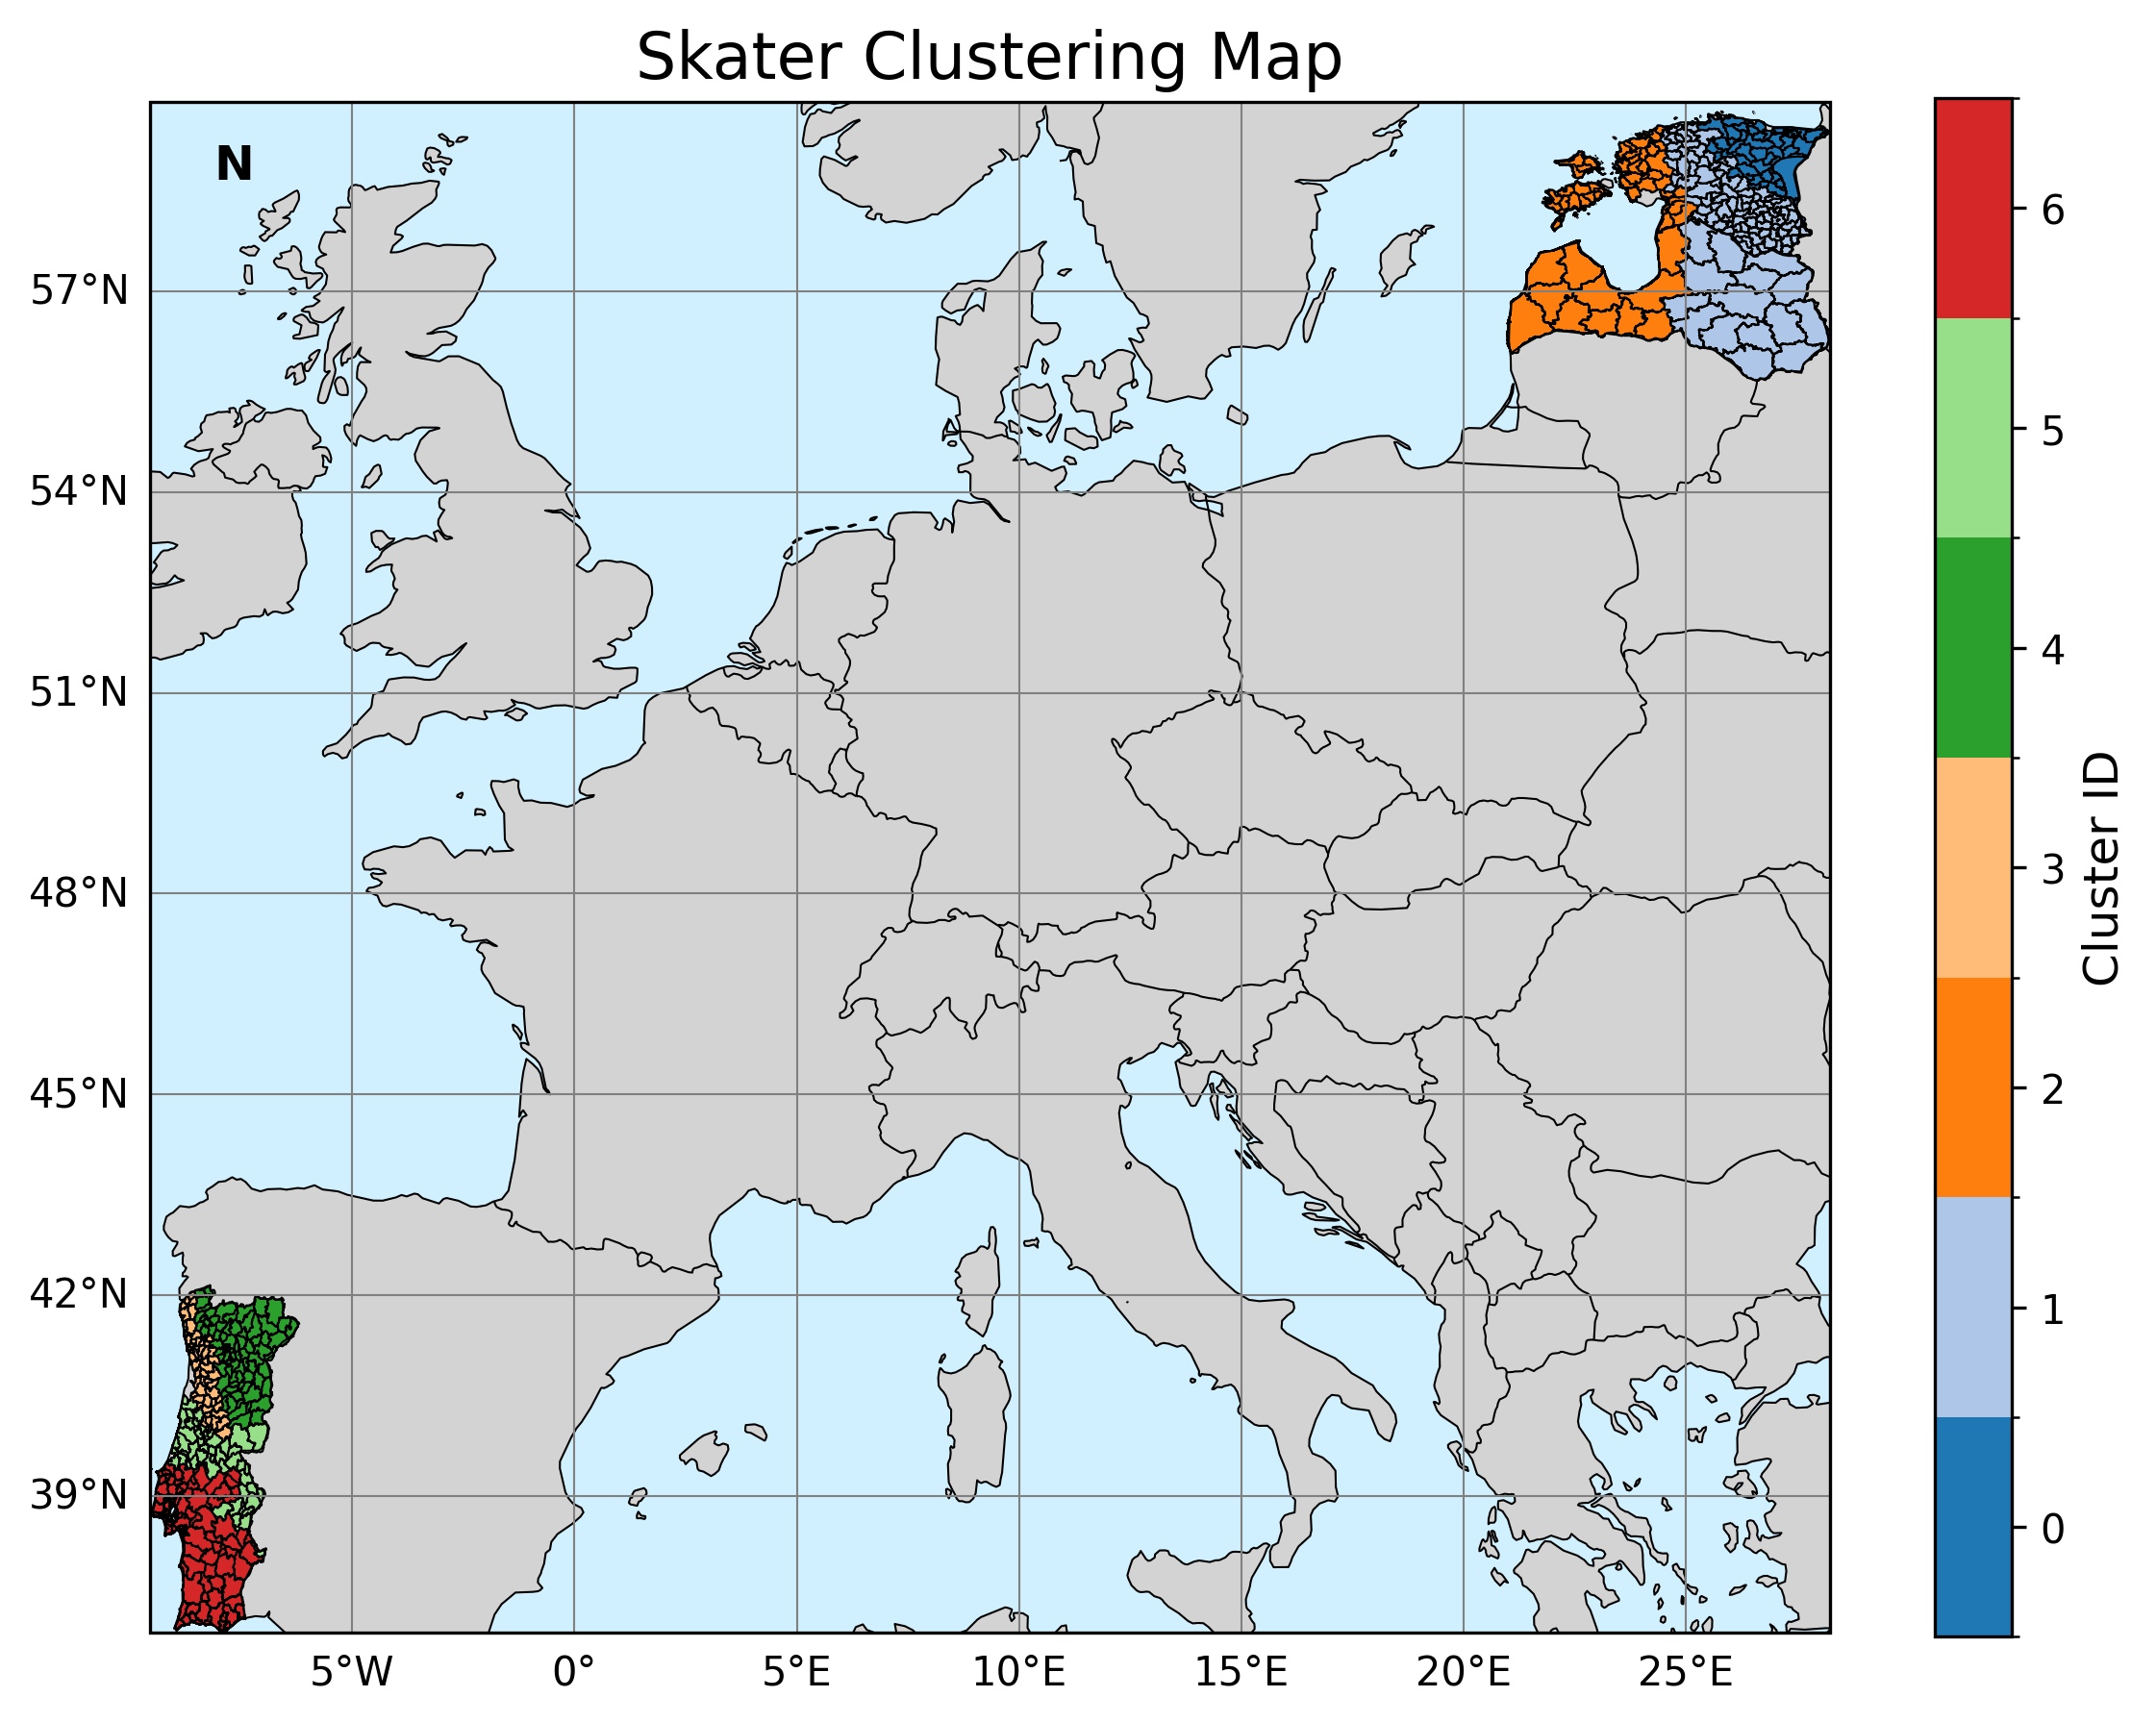

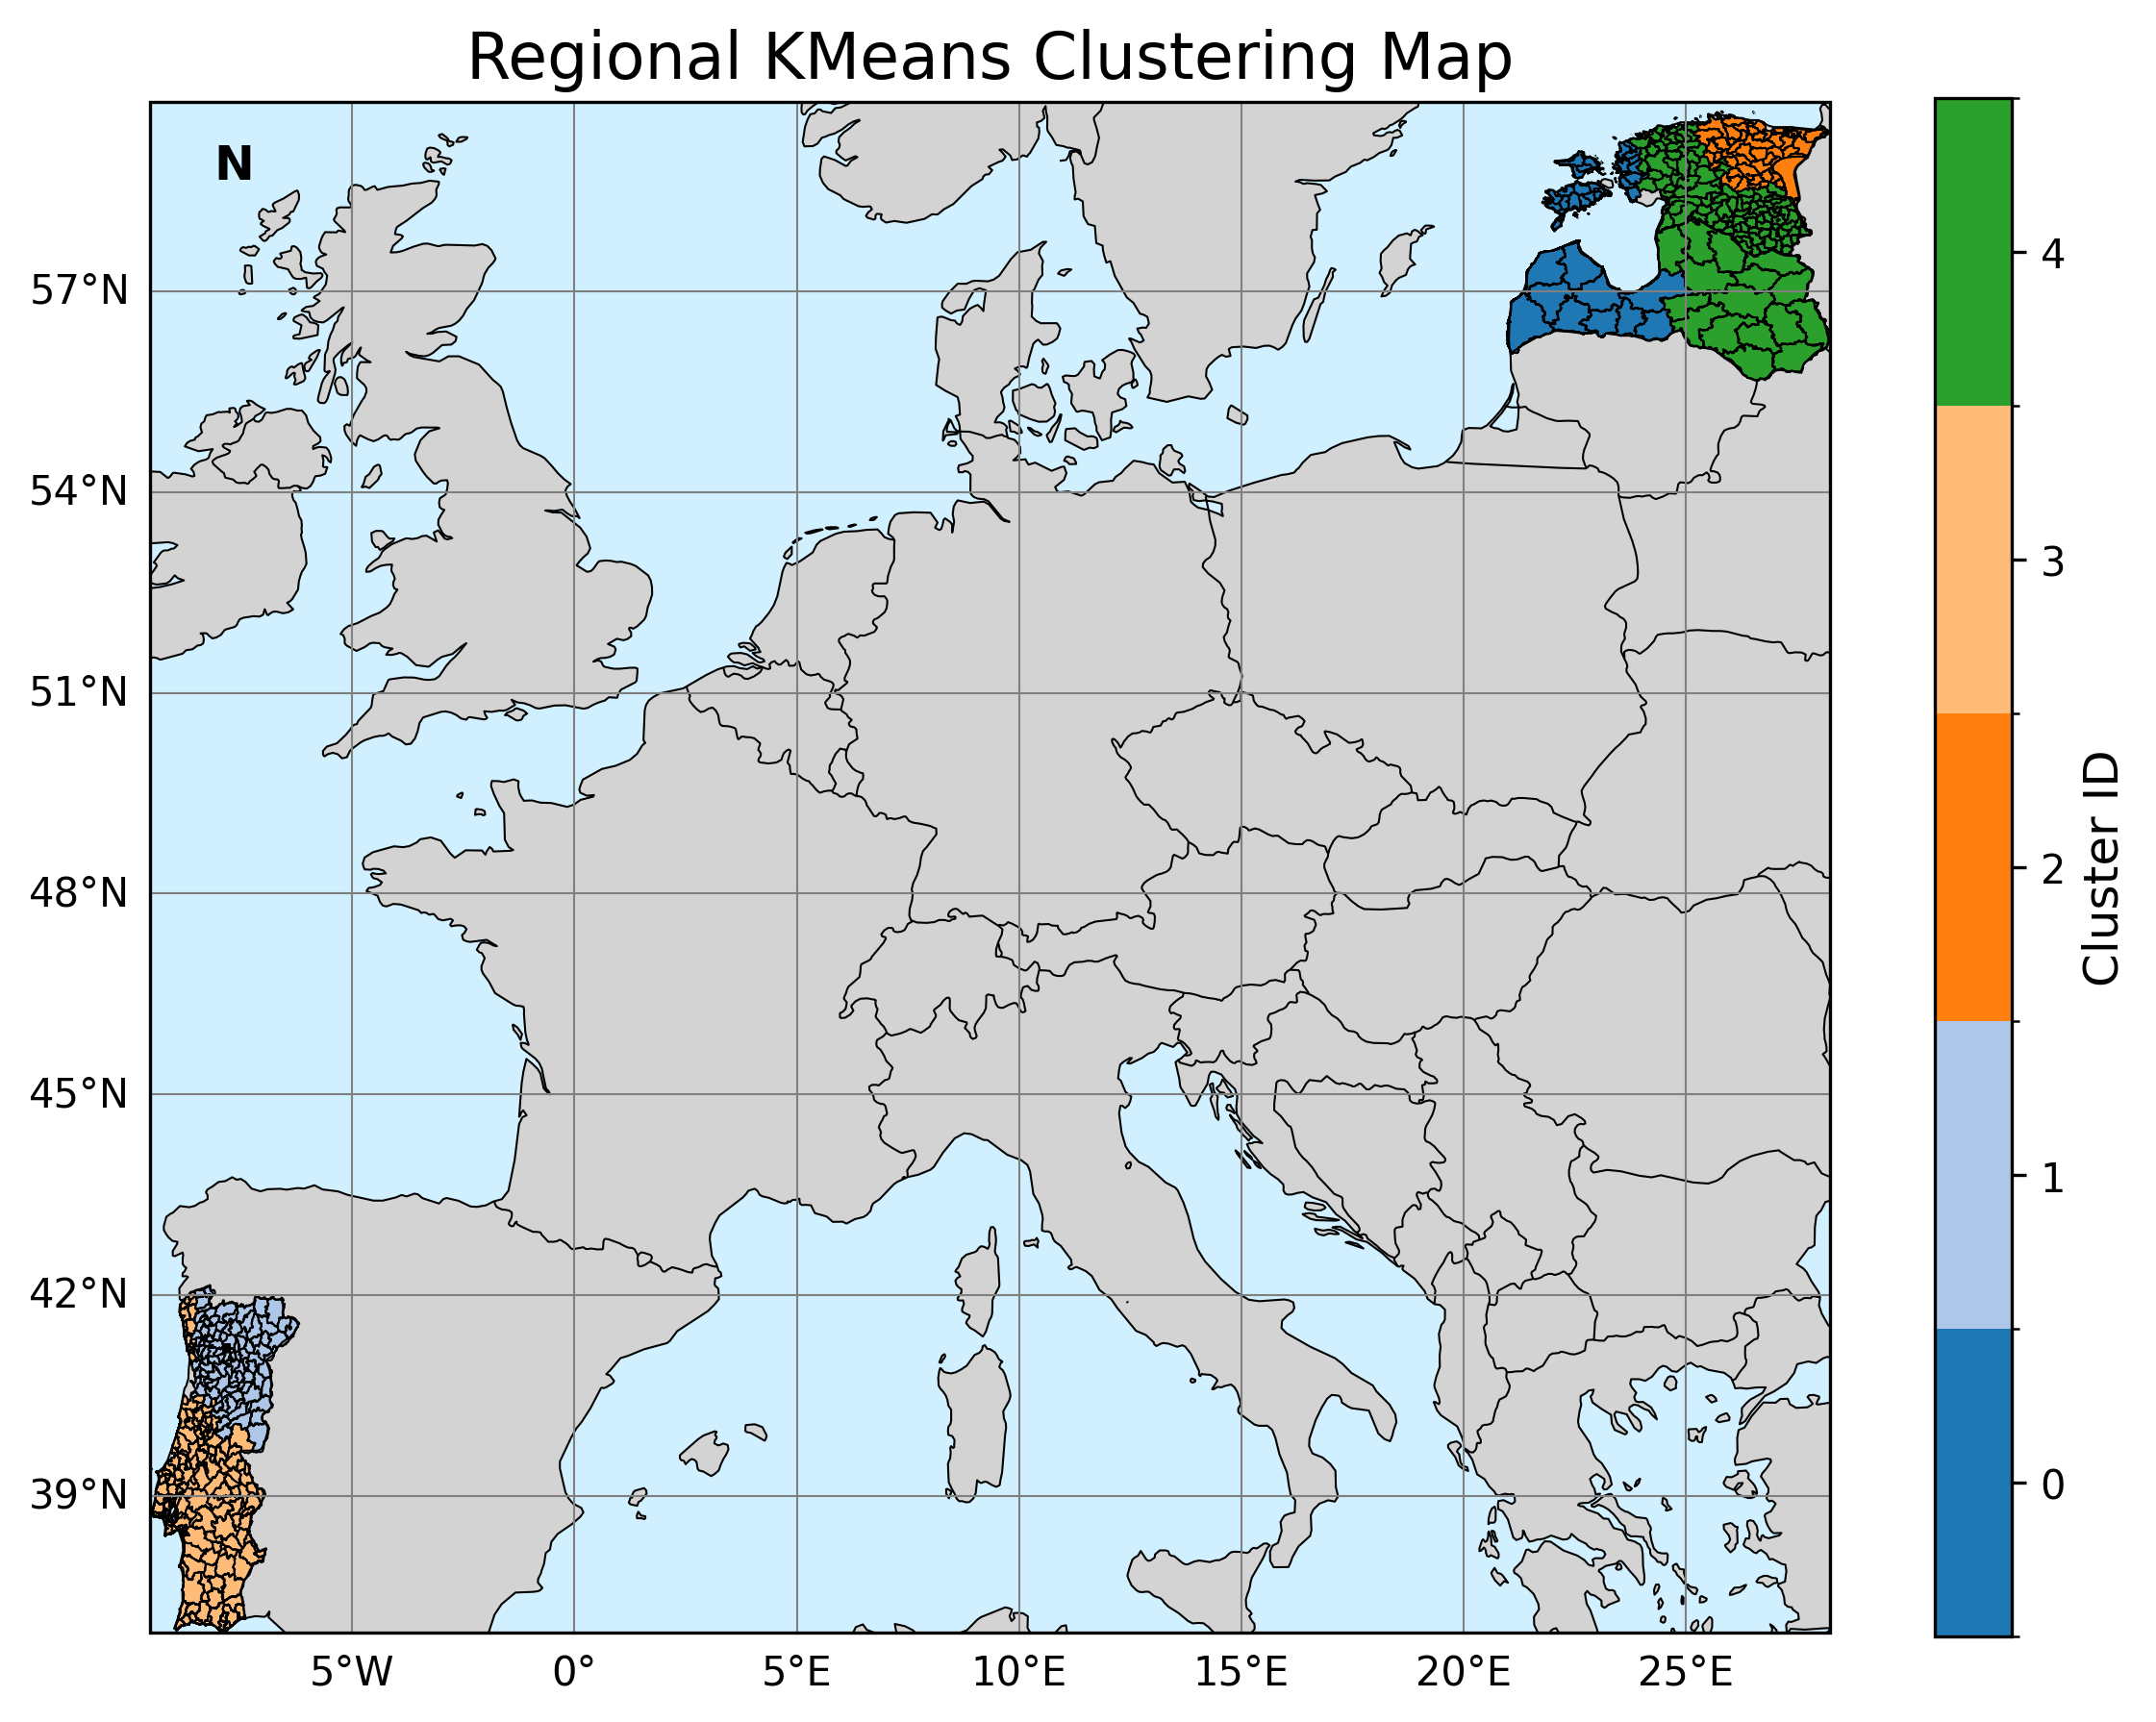

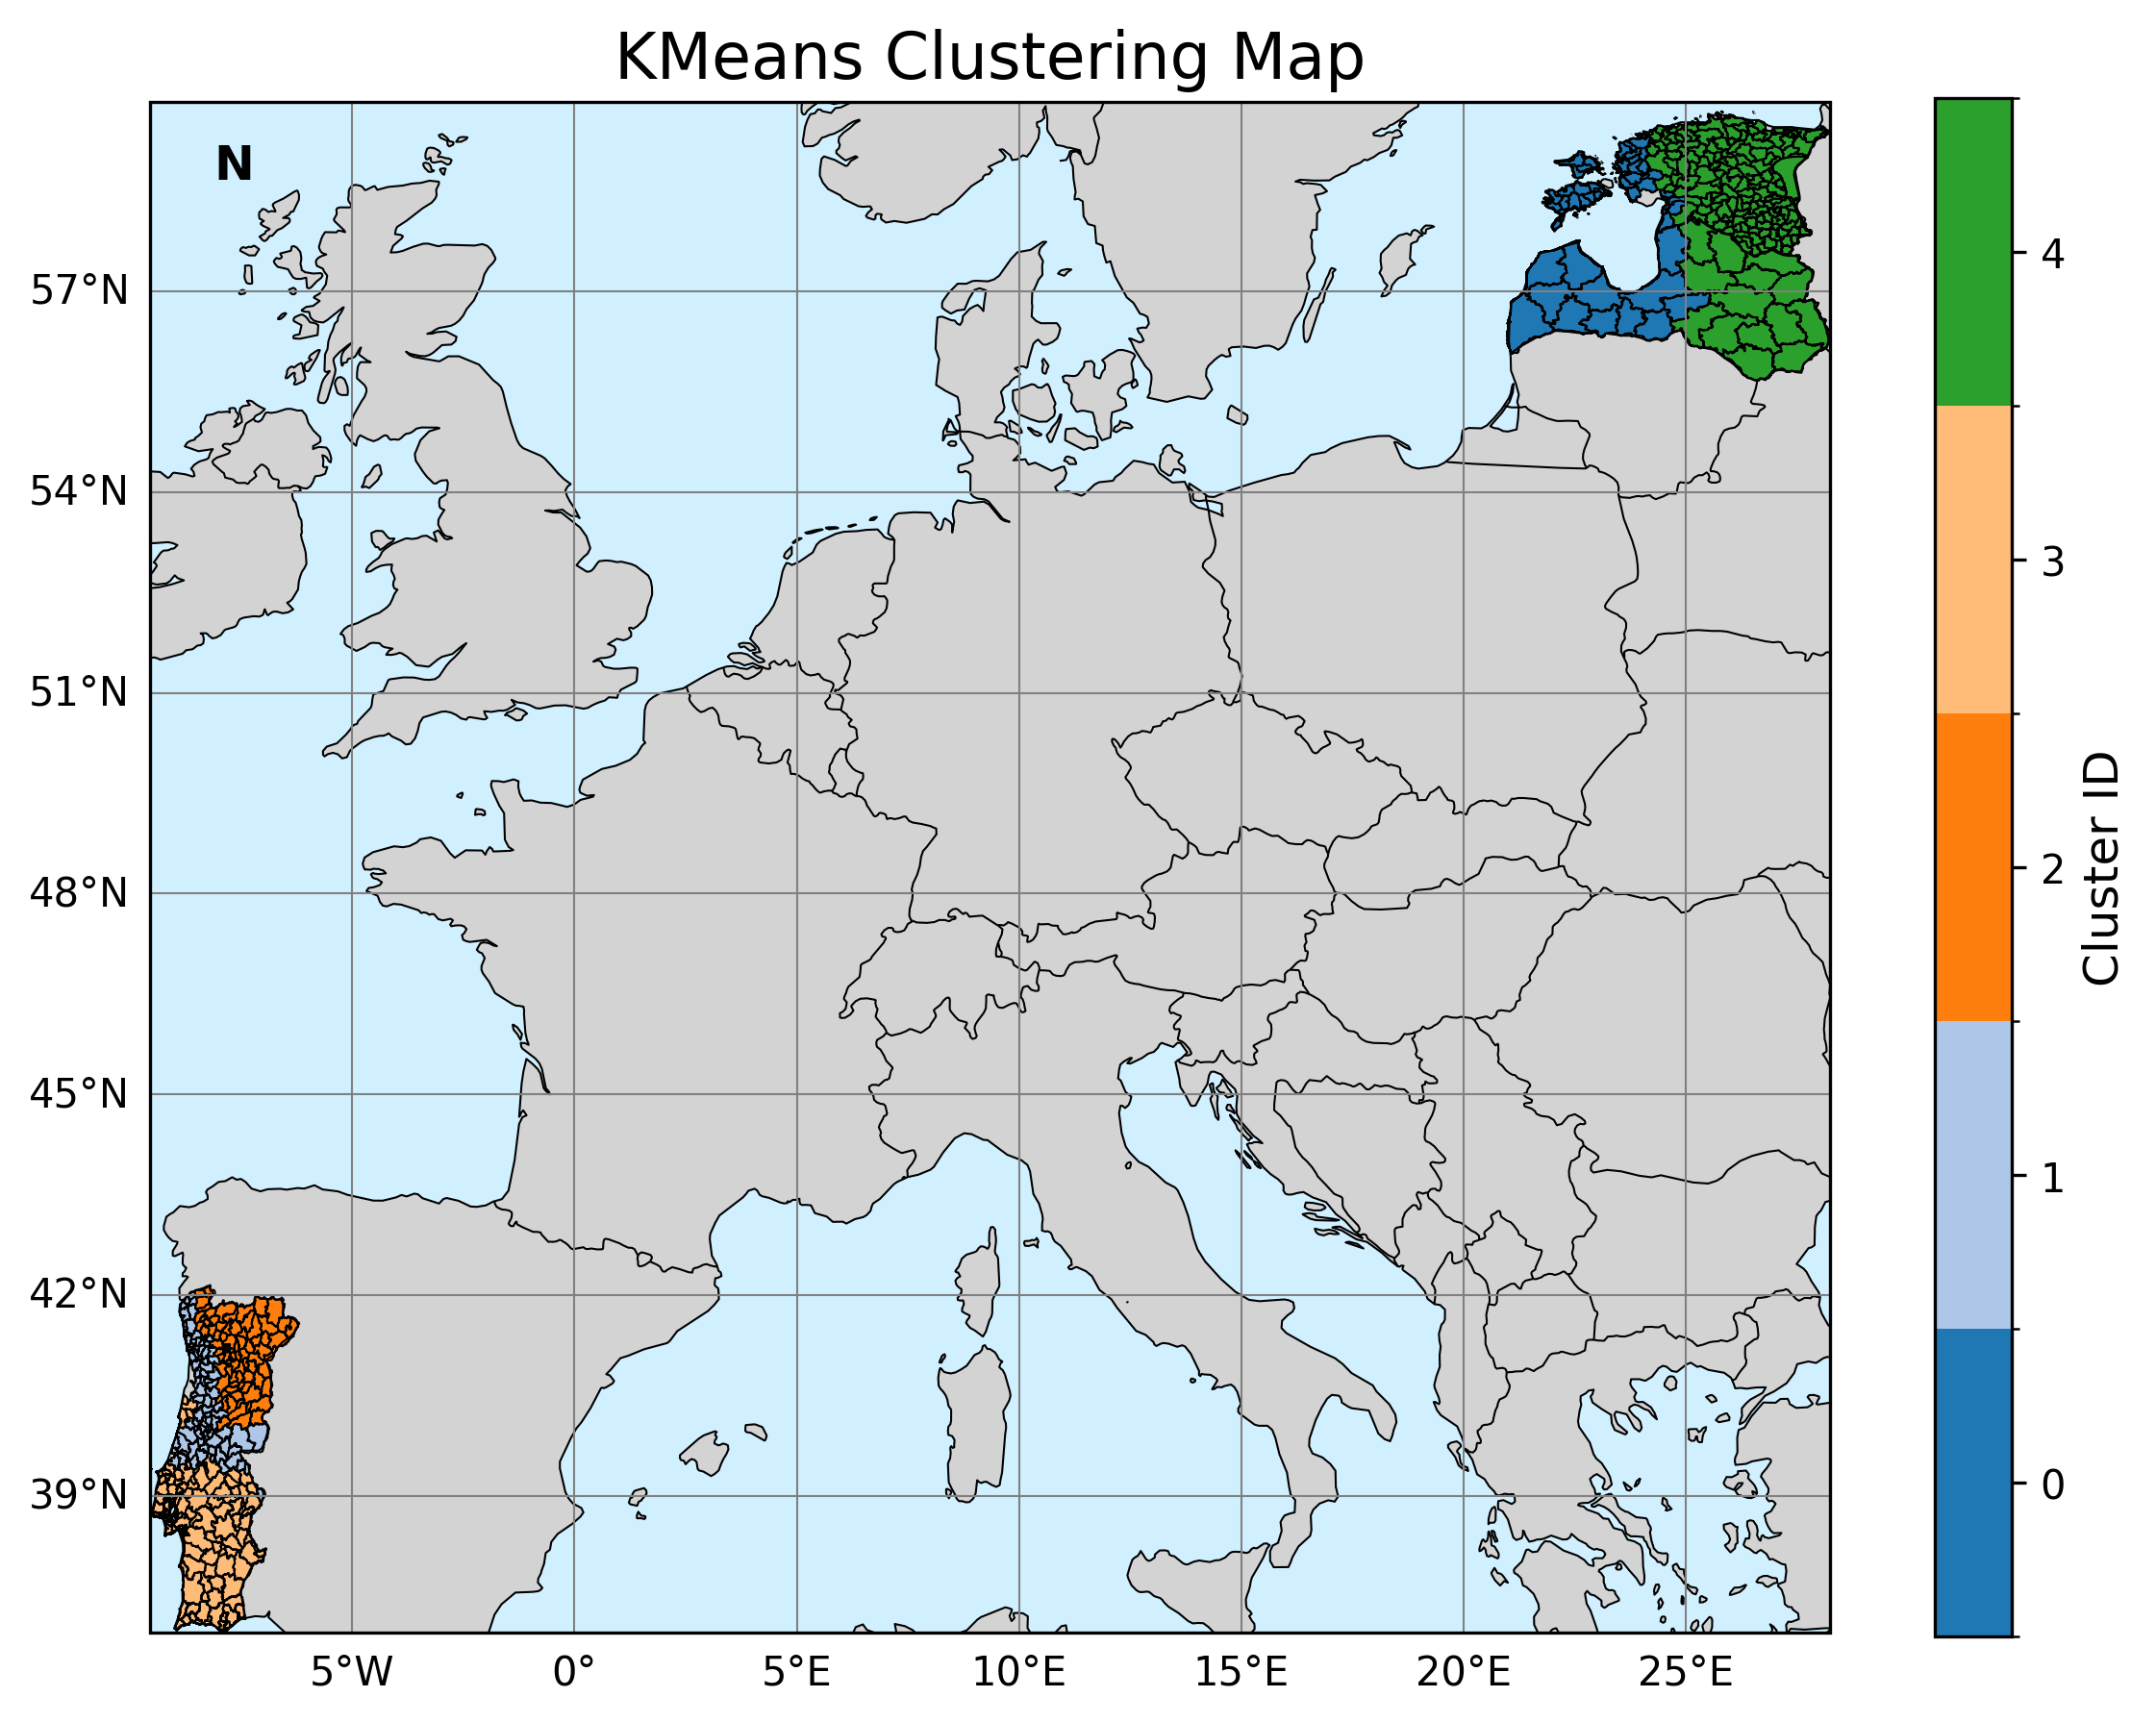

Temporal Interpolation (366, 44, 129)
Reshaped data shape after two swaps and reshaping: (5676, 366)
nans 1856
Temporal Interpolation (366, 44, 129)
Reshaped data shape after two swaps and reshaping: (5676, 366)
nans 1856
Temporal Interpolation (52, 44, 129)
Reshaped data shape after two swaps and reshaping: (5676, 52)
nans 1751
Temporal Interpolation (366, 104, 67)
Reshaped data shape after two swaps and reshaping: (6968, 366)
nans 940
Temporal Interpolation (366, 104, 67)
Reshaped data shape after two swaps and reshaping: (6968, 366)
nans 940
Temporal Interpolation (52, 104, 67)
Reshaped data shape after two swaps and reshaping: (6968, 52)
nans 1181
Temporal Interpolation (366, 50, 146)
Reshaped data shape after two swaps and reshaping: (7300, 366)
nans 1049
Temporal Interpolation (366, 50, 146)
Reshaped data shape after two swaps and reshaping: (7300, 366)
nans 1049
Temporal Interpolation (52, 50, 146)
Reshaped data shape after two swaps and reshaping: (7300, 52)
nans 1194
Computing

100%|██████████| 15144/15144 [57:36<00:00,  4.38it/s] 


Variable 2/3
ts 0 1
ts 1 1
ts 2 1
ts 3 1
ts 4 1
ts 5 1
ts 6 1
ts 7 1
ts 8 1
ts 9 1
ts 10 1
ts 11 1
ts 12 1
ts 13 1
ts 14 1
ts 15 1
ts 16 1
ts 17 1
ts 18 1
ts 19 1
ts 20 1
ts 21 1
ts 22 1
ts 23 1
ts 24 1
ts 25 1
ts 26 1
ts 27 1
ts 28 1
ts 29 1
ts 30 1
ts 31 1
ts 32 1
ts 33 1
ts 34 1
ts 35 1
ts 36 1
ts 37 1
ts 38 1
ts 39 1
ts 40 1
ts 41 1
ts 42 1
ts 43 1
ts 44 1
ts 45 1
ts 46 1
ts 47 1
ts 48 1
ts 49 1
ts 50 1
ts 51 1
ts 52 1
ts 53 1
ts 54 1
ts 55 1
ts 56 1
ts 57 1
ts 58 1
ts 59 1
ts 60 1
ts 61 1
ts 62 1
ts 63 1
ts 64 1
ts 65 1
ts 66 1
ts 67 1
ts 68 1
ts 69 1
ts 70 1
ts 71 1
ts 72 1
ts 73 1
ts 74 1
ts 75 1
ts 76 1
ts 77 1
ts 78 1
ts 79 1
ts 80 1
ts 81 1
ts 82 1
ts 83 1
ts 84 1
ts 85 1
ts 86 1
ts 87 1
ts 88 1
ts 89 1
ts 90 1
ts 91 1
ts 92 1
ts 93 1
ts 94 1
ts 95 1
ts 96 1
ts 97 1
ts 98 1
ts 99 1
ts 100 1
ts 101 1
ts 102 1
ts 103 1
ts 104 1
ts 105 1
ts 106 1
ts 107 1
ts 108 1
ts 109 1
ts 110 1
ts 111 1
ts 112 1
ts 113 1
ts 114 1
ts 115 1
ts 116 1
ts 117 1
ts 118 1
ts 119 1
ts 120 1
ts 121 1

100%|██████████| 15144/15144 [57:28<00:00,  4.39it/s] 


Variable 3/3
ts 0 2
ts 1 2
ts 2 2
ts 3 2
ts 4 2
ts 5 2
ts 6 2
ts 7 2
ts 8 2
ts 9 2
ts 10 2
ts 11 2
ts 12 2
ts 13 2
ts 14 2
ts 15 2
ts 16 2
ts 17 2
ts 18 2
ts 19 2
ts 20 2
ts 21 2
ts 22 2
ts 23 2
ts 24 2
ts 25 2
ts 26 2
ts 27 2
ts 28 2
ts 29 2
ts 30 2
ts 31 2
ts 32 2
ts 33 2
ts 34 2
ts 35 2
ts 36 2
ts 37 2
ts 38 2
ts 39 2
ts 40 2
ts 41 2
ts 42 2
ts 43 2
ts 44 2
ts 45 2
ts 46 2
ts 47 2
ts 48 2
ts 49 2
ts 50 2
ts 51 2
ts 52 2
ts 53 2
ts 54 2
ts 55 2
ts 56 2
ts 57 2
ts 58 2
ts 59 2
ts 60 2
ts 61 2
ts 62 2
ts 63 2
ts 64 2
ts 65 2
ts 66 2
ts 67 2
ts 68 2
ts 69 2
ts 70 2
ts 71 2
ts 72 2
ts 73 2
ts 74 2
ts 75 2
ts 76 2
ts 77 2
ts 78 2
ts 79 2
ts 80 2
ts 81 2
ts 82 2
ts 83 2
ts 84 2
ts 85 2
ts 86 2
ts 87 2
ts 88 2
ts 89 2
ts 90 2
ts 91 2
ts 92 2
ts 93 2
ts 94 2
ts 95 2
ts 96 2
ts 97 2
ts 98 2
ts 99 2
ts 100 2
ts 101 2
ts 102 2
ts 103 2
ts 104 2
ts 105 2
ts 106 2
ts 107 2
ts 108 2
ts 109 2
ts 110 2
ts 111 2
ts 112 2
ts 113 2
ts 114 2
ts 115 2
ts 116 2
ts 117 2
ts 118 2
ts 119 2
ts 120 2
ts 121 2

100%|██████████| 15144/15144 [56:59<00:00,  4.43it/s] 


dim 3
dim 4
dim 5


In [ ]:
from shapely.geometry import Point
# os.makedirs(r'E:\CPUS\cpus\notebooks\normalized_ts_plots', exist_ok=True)
boundary_gpkg = r'C:\Users\shaba\Downloads\gadm_410-gpkg\gadm_410.gpkg'
countries = list(set(key[1] for key in datasets_all.keys()))
crops = list(set(key[0] for key in datasets_all.keys()))

variables_init = [
    # 'fpar.nc',
    # 'ndvi.nc',
    # 'gcvi.nc',
    'cpc-tmax.nc',
    'cpc-tmin.nc',
    'esi-4wk.nc'
]

def visualize_and_save_distance_matrices(dist_matrices, combined_dist, output_dir):
    os.makedirs(output_dir, exist_ok=True)
    
    for idx, dist in enumerate(dist_matrices):
        plt.figure(figsize=(8, 6))
        plt.imshow(dist, cmap='viridis', interpolation='nearest')
        plt.colorbar(label='Normalized DTW Distance')
        plt.title(f'Distance Matrix Variable {idx + 1}')
        plt.xlabel('Sample Index')
        plt.ylabel('Sample Index')
        plt.tight_layout()
        plt.savefig(os.path.join(output_dir, f'dist_matrix_var_{idx + 1}.png'))
        plt.close()

    plt.figure(figsize=(8, 6))
    plt.imshow(combined_dist, cmap='viridis', interpolation='nearest')
    plt.colorbar(label='Mean Normalized DTW Distance')
    plt.title('Combined Distance Matrix (Mean over variables)')
    plt.xlabel('Sample Index')
    plt.ylabel('Sample Index')
    plt.tight_layout()
    plt.savefig(os.path.join(output_dir, 'combined_dist_matrix.png'))
    plt.close()

def normalize_ts(ts):
    ts = np.asarray(ts).reshape(-1, 1)
    return StandardScaler().fit_transform(ts).flatten()

def compute_dtw_distance_matrix(time_series_list):
    n = len(time_series_list)
    dist_matrix = np.zeros((n, n))
    for i in tqdm(range(n)):
        for j in range(i + 1, n):
            dist = dtw.distance_fast(time_series_list[i], time_series_list[j])
            dist_matrix[i, j] = dist
            dist_matrix[j, i] = dist
    return dist_matrix

def resample_to_20d(ts, original_freq):
    if not isinstance(ts, pd.Series):
        ts = pd.Series(ts)
    if not isinstance(ts.index, pd.DatetimeIndex):
        ts.index = pd.date_range(start='2000-01-01', periods=len(ts), freq=original_freq)
    return ts.resample('20D').mean().dropna()

def compute_dtw_distance_matrix(time_series_list):
    n = len(time_series_list)
    dist_matrix = np.zeros((n, n))
    for i in tqdm(range(n)):
        for j in range(i + 1, n):
            dist = dtw.distance_fast(time_series_list[i], time_series_list[j])
            dist_matrix[i, j] = dist
            dist_matrix[j, i] = dist
    return dist_matrix

def pairwise_dtw(i, j, time_series_list):
    dist = dtw.distance_fast(time_series_list[i], time_series_list[j])
    return (i, j, dist)

def compute_dtw_distance_matrix_parallel(time_series_list, n_jobs=-1):
    n = len(time_series_list)
    dist_matrix = np.zeros((n, n))
    
    pairs = [(i, j) for i in range(n) for j in range(i + 1, n)]
    
    results = Parallel(n_jobs=n_jobs)(
        delayed(pairwise_dtw)(i, j, time_series_list) for i, j in tqdm(pairs)
    )
    
    for i, j, dist in results:
        dist_matrix[i, j] = dist
        dist_matrix[j, i] = dist
        
    return dist_matrix

from sklearn.manifold import MDS
import numpy as np

def select_mds_n_components(data, max_components=10, threshold=0.05):
    stress_scores = []
    dims = range(3, max_components + 1)

    for d in dims:
        print('dim', d)
        mds = MDS(n_components=d, dissimilarity='euclidean', random_state=42, normalized_stress='auto')
        mds.fit(data)
        stress_scores.append(mds.stress_)

    stress_scores = np.array(stress_scores)

    # Compute percentage drop between successive dimensions
    drop_rates = np.diff(stress_scores) / stress_scores[:-1]

    # Find the elbow: largest relative drop before plateau
    elbow_candidates = np.where(np.abs(drop_rates) < threshold)[0]
    if len(elbow_candidates) > 0:
        best_dim = elbow_candidates[0] + 1  # +1 due to diff reducing index by 1
    else:
        best_dim = np.argmin(stress_scores) + 1

    return best_dim

for crop in crops:
    all_vars_time_series = []
    all_lat_lon = []
    all_masks = []

    for country in countries:
        crop_country_vars = []
        var_list = []

        for (crop_key, country_key, vars), data in datasets_all.items():
            if country_key == country and crop_key == crop:
                crop_country_vars.append(data)
                var_list.append(vars)

        filtered_data_list, lat_lon, mask = prep_for_clustering(
            crop_country_vars, var_list, country, shapes, 'train', None
        )

        all_vars_time_series.append(filtered_data_list)
        all_lat_lon.append(lat_lon)
        all_masks.append(mask)

    n_vars = len(all_vars_time_series[0])
    combined_vars = []
    for v in range(n_vars):
        combined_var_data = np.vstack([country_vars[v] for country_vars in all_vars_time_series])
        combined_vars.append(combined_var_data)

    combined_lat_lon_all = np.vstack(all_lat_lon)
    combined_mask_all = np.hstack(all_masks)

    dist_matrices = []
    print('Computing DTW distances on 20-day resampled data...')
    for idx, var_data in enumerate(combined_vars):
        print(f"Variable {idx + 1}/{len(combined_vars)}")
        resampled_ts_list = [np.asarray(resample_to_20d(ts, str(int(data_freq_i[idx]))+'D'), dtype=np.float64) for ts in var_data]

        clipped_ts_list = []
        for ts_idx, ts in enumerate(resampled_ts_list):
            print('ts', ts_idx, idx)
            q1 = np.percentile(ts, 25)
            q3 = np.percentile(ts, 75)
            iqr = q3 - q1
            lb = q1 - 1.5 * iqr
            ub = q3 + 1.5 * iqr
            clipped = np.clip(ts, lb, ub)
            clipped_ts_list.append(clipped)

        arr = np.vstack(clipped_ts_list)
        global_min = np.min(arr)
        global_max = np.max(arr)
        print('var', idx)
        print('global_min', global_min)
        print('global_min', global_max)
        # norm_arr = 2 * (arr - global_min) / (global_max - global_min) - 1
        norm_arr = arr
        normalized_ts_list = [norm_arr[i, :] for i in range(norm_arr.shape[0])]
        sample_indices = random.sample(range(len(normalized_ts_list)), min(20, len(normalized_ts_list)))
        plt.figure(figsize=(10, 6))
        for i in sample_indices:
            plt.plot(normalized_ts_list[i], alpha=0.7)
        plt.title(f'Normalized TS Samples - Variable {idx + 1}')
        plt.xlabel('Time Index')
        plt.ylabel('Normalized Value')
        plt.grid(True)
        plt.tight_layout()
        plt.savefig(rf'{paper_directory}\{crop}-variable_{idx + 1}.png')
        plt.close()
        dist = compute_dtw_distance_matrix(normalized_ts_list)
        max_dist = np.max(dist)
        if max_dist > 0:
            dist = dist / max_dist  # Normalize distances to [0,1]
        dist_matrices.append(dist)

    np.savez_compressed(rf'{paper_directory}\{crop}-dist_matrices_dtw.npz', *dist_matrices)
    dist_matrices = [dm for dm in dist_matrices]
    combined_dist = np.mean(dist_matrices, axis=0)
    visualize_and_save_distance_matrices(dist_matrices, combined_dist, rf'{paper_directory}\distance_matrices_visuals')

    best_n = select_mds_n_components(combined_dist)
    print(f"Selected number of MDS components: {best_n}")
    mds = MDS(n_components=best_n, dissimilarity='euclidean', random_state=42, normalized_stress='auto')
    data_mds = mds.fit_transform(combined_dist)
    # Combine MDS embedding with lat/lon
    combined_features = np.hstack([data_mds, combined_lat_lon_all])

    # Aggregate if needed
    if level == 'native':
        shp_data = combined_features
        shp_coords = combined_lat_lon_all
    else:
        shp_data, shp_names, shp_df, shp_coords, shp_org = aggregator(
            combined_features, combined_lat_lon_all, shps, level
        )
        shp_coords = np.array([[pt.y, pt.x] for pt in shp_coords if pt is not None])


    params = {'n_clusters': 4, 'k_neighbors': 10, 'optimize': True}
    # gat_clusters, embeddings = GAT_DEC_clustering(shp_coords, [shp_data], params)
    # fast_skater_clusters = fast_skater(shp_coords, [shp_data], params)
    skater_clusters = skater_clustering(shp_coords, [shp_data], params)
    regionalkmeans_clusters = regional_kmeansheuristic(shp_coords, [shp_data], params)
    kmeans_clusters = kmeans_clustering(shp_coords, [shp_data], params)

    gdf = gpd.GeoDataFrame({
        "cluster": skater_clusters,
        "name": shp_names[:len(skater_clusters)]
    }, geometry=shp_org, crs="EPSG:4326")
    gdf = gdf.merge(shps_combined, left_on="name", right_on=level)
    gdf['geometry'] = gdf['geometry_x']
    gdf = gdf.drop(columns=['geometry_x', 'geometry_y'])
    gdf = gpd.GeoDataFrame(gdf, geometry='geometry', crs="EPSG:4326")
    gdf.to_file(rf'{out_shp_directory}\{crop}_skater_clustering.geojson', driver="GeoJSON")
    plot_clusters(gdf, boundary_gpkg, "cluster", title="Skater Clustering Map", output_path=rf'{paper_directory}\{crop}_skater_clustering.png')
    plot_umap_clusters(shp_data, skater_clusters, output_path=rf'{paper_directory}\{crop}_skater_clustering_umap.png')
    
    gdf = gpd.GeoDataFrame({
        "cluster": regionalkmeans_clusters,
        "name": shp_names[:len(regionalkmeans_clusters)]
    }, geometry=shp_org, crs="EPSG:4326")
    gdf = gdf.merge(shps_combined, left_on="name", right_on=level)
    gdf['geometry'] = gdf['geometry_x']
    gdf = gdf.drop(columns=['geometry_x', 'geometry_y'])
    gdf = gpd.GeoDataFrame(gdf, geometry='geometry', crs="EPSG:4326")
    gdf.to_file(rf'{out_shp_directory}\{crop}_regionalkmeans_cluster.geojson', driver="GeoJSON")
    plot_clusters(gdf, boundary_gpkg, "cluster", title="Regional KMeans Clustering Map", output_path=rf'{paper_directory}\{crop}_regionalkmeans_cluster.png')
    plot_umap_clusters(shp_data, regionalkmeans_clusters, output_path=rf'{paper_directory}\{crop}_regional_clustering_umap.png')

    gdf = gpd.GeoDataFrame({
        "cluster": kmeans_clusters,
        "name": shp_names[:len(kmeans_clusters)]
    }, geometry=shp_org, crs="EPSG:4326")
    gdf = gdf.merge(shps_combined, left_on="name", right_on=level)
    gdf['geometry'] = gdf['geometry_x']
    gdf = gdf.drop(columns=['geometry_x', 'geometry_y'])
    gdf = gpd.GeoDataFrame(gdf, geometry='geometry', crs="EPSG:4326")
    gdf.to_file(rf'{out_shp_directory}\{crop}_kmeans_clusters.geojson', driver="GeoJSON")
    plot_clusters(gdf, boundary_gpkg, "cluster", title="KMeans Clustering Map", output_path=rf'{paper_directory}\{crop}_kmeans_clusters.png')
    plot_umap_clusters(shp_data, kmeans_clusters, output_path=rf'{paper_directory}\{crop}_kmeans_clustering_umap.png')

    # gdf = gpd.GeoDataFrame({
    #     "cluster": community_clusters,
    #     "name": shp_names[:len(community_clusters)]
    # }, geometry=shp_org, crs="EPSG:4326")
    # gdf = gdf.merge(shps_combined, left_on="name", right_on=level)
    # gdf['geometry'] = gdf['geometry_x']
    # gdf = gdf.drop(columns=['geometry_x', 'geometry_y'])
    # gdf = gpd.GeoDataFrame(gdf, geometry='geometry', crs="EPSG:4326")
    # gdf.to_file(rf'{out_shp_directory}\{crop}_community_clusters.geojson', driver="GeoJSON")
    # plot_clusters(gdf, boundary_gpkg, "cluster", title="Community Clustering Map", output_path=rf'{paper_directory}\{crop}_community_clusters.png')
    # plot_umap_clusters(shp_data, community_clusters, output_path=rf'{paper_directory}\{crop}_community_clustering_umap.png')

    # gdf = gpd.GeoDataFrame({
    #     "cluster": fast_skater_clusters,
    #     "name": shp_names[:len(fast_skater_clusters)]
    # }, geometry=shp_org, crs="EPSG:4326")
    # gdf = gdf.merge(shps_combined, left_on="name", right_on=level)
    # gdf['geometry'] = gdf['geometry_x']
    # gdf = gdf.drop(columns=['geometry_x', 'geometry_y'])
    # gdf = gpd.GeoDataFrame(gdf, geometry='geometry', crs="EPSG:4326")
    # gdf.to_file(rf'{out_shp_directory}\{crop}_fast_skater_clusters.geojson', driver="GeoJSON")
    # plot_clusters(gdf, boundary_gpkg, "cluster", title="Fast Skater Clustering Map", output_path=rf'{paper_directory}\{crop}_fast_skater_clusters.png')
    # plot_tsne_clusters(shp_data, fast_skater_clusters, output_path=rf'{paper_directory}\{crop}_fast_skater_clusters_tsne.png')
    # plot_pca_clusters(shp_data, fast_skater_clusters, output_path=rf'{paper_directory}\{crop}_fast_skater_clusters_pca.png')

    # gdf = gpd.GeoDataFrame({
    #     "cluster": gat_clusters,
    #     "name": shp_names[:len(gat_clusters)]
    # }, geometry=shp_org, crs="EPSG:4326")
    # gdf = gdf.merge(shps_combined, left_on="name", right_on=level)
    # gdf['geometry'] = gdf['geometry_x']
    # gdf = gdf.drop(columns=['geometry_x', 'geometry_y'])
    # gdf = gpd.GeoDataFrame(gdf, geometry='geometry', crs="EPSG:4326")
    # gdf.to_file(rf'{out_shp_directory}\{crop}_gat_clusters.geojson', driver="GeoJSON")
    # plot_clusters(gdf, boundary_gpkg, "cluster", title="GAT Clustering Map", output_path=rf'{paper_directory}\{crop}_gat_clusters.png')
    

In [22]:
! pip install dtaidistance

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/1.0 MB ? eta -:--:--
   - -------------------------------------- 0.0/1.0 MB 1.9 MB/s eta 0:00:01
   -------------------- ------------------- 0.5/1.0 MB 6.7 MB/s eta 0:00:01
   ---------------------------------------- 1.0/1.0 MB 8.2 MB/s eta 0:00:00
